# Laboratorio_3_grupo_4: Reidentificación de personas

## CO-SSL (CO-BYOL) para re-identificación de personas sin etiquetas en Market-1501

**Curso:** Deep Learning, Maestría en Ciencia de Datos e IA (UTEC) · **Grupo 4**
**Integrantes:** _(Yelsin Huancachoque · Bruno Chihuan · Julio Mogollon · Diego Perez)_

**Paper:** Aubret, Teulière y Triesch (2026). *Seeing the whole in the parts with self-supervised representation learning.* Neurocomputing 675, 132973.

**Idea central:** además de la pérdida BYOL global↔global, cada representación **local** (los n² vectores del mapa antes del avgpool) se alinea con la representación **global** de la otra vista. En Re-ID, cada parte del cuerpo debe "ver" a la persona completa.

**Contenido del notebook:**

0. Procedimiento de ejecución en KHIPU
1. Configuración
2. Datos
3. Augmentaciones
4. Modelo
5. Pérdida
6. Entrenamiento
7. Evaluación
8. Experimentos en validación y ablación
9. Reentrenamiento final y test
10. Análisis
11. Comparación global de todos los experimentos (R0–R10), incluida la evaluación en test de R9 y R10

## 0. Procedimiento de ejecución en KHIPU

KHIPU es el clúster de UTEC. Su documentación oficial está en https://docs.khipu.utec.edu.pe y la mesa de ayuda en https://servicedesk.utec.edu.pe.

Este notebook también funciona en Google Colab y en una PC local; el entorno se detecta solo.

### 0.1 Datos clave de KHIPU para este laboratorio

| Tema | Valor | Consecuencia para nosotros |
|---|---|---|
| Acceso | `ssh <usuario>@khipu.utec.edu.pe` · Open OnDemand en https://ood.khipu.utec.edu.pe | La primera vez hay que entrar por SSH: ahí se crea el `/home` |
| Internet | Solo el **nodo de acceso** tiene salida a internet | Instalar paquetes y **descargar los pesos de ImageNet antes** de lanzar jobs |
| Nodo de acceso | No es para cómputo | Nunca entrenar ahí: siempre con `sbatch`, `srun` o OnDemand |
| Particiones | `debug-gpu` (máx. 30 min, para pruebas) y `gpu` (producción) | Probar en `debug-gpu` y entrenar en `gpu` |
| GPU | T4 16 GB, RTX A6000 48 GB, A100 40 GB, compartidas por *shards* | No se reserva la GPU completa: la memoria se comparte con otros usuarios |
| Cuenta de posgrado | 32 cores, 98 GB de RAM, **8 shards de GPU**, **8 h máximo por job** | Pedir como máximo `--gres=shard:8` y `--time=08:00:00` |
| Respaldo | Los discos de KHIPU **no tienen backup** | Descargar los resultados al terminar |

Para ver los recursos exactos de tu cuenta, ejecuta `myaccount` en KHIPU.

### 0.2 Subir los archivos (desde Windows, en PowerShell)

Reemplaza `<usuario>` por tu usuario de KHIPU. Ojo: tres contraseñas incorrectas seguidas bloquean tu IP.

```powershell
ssh <usuario>@khipu.utec.edu.pe "mkdir -p ~/lab3/logs"
scp -r "C:\Users\julio\Downloads\Dataset" <usuario>@khipu.utec.edu.pe:~/lab3/
scp "Laboratorio_3_grupo_4_Reidentificacion_de_personas.ipynb" "Laboratorio_3_grupo_4_khipu.sbatch" <usuario>@khipu.utec.edu.pe:~/lab3/
```

La estructura esperada en KHIPU es esta (si usas otra, define `LAB3_ROOT`):

```
~/lab3/
├── Dataset/            training.h5, validation.h5, testing.h5
├── logs/               salidas de los jobs (debe existir antes de sbatch)
├── runs/               checkpoints, resultados y figuras (se crea solo)
├── venv/               entorno de Python
├── Laboratorio_3_grupo_4_Reidentificacion_de_personas.ipynb
└── Laboratorio_3_grupo_4_khipu.sbatch
```

### 0.3 Crear el entorno de Python (una sola vez, en el nodo de acceso)

Se usa el módulo `python3/3.13.2`, que es el mismo que usa Jupyter en OnDemand. Si el kernel se crea con otra versión, puede aparecer en Jupyter pero no iniciar.

```bash
ssh <usuario>@khipu.utec.edu.pe
module load python3/3.13.2
python3 -m venv ~/lab3/venv
source ~/lab3/venv/bin/activate
pip install --upgrade pip
pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126
pip install h5py matplotlib pandas ipykernel nbconvert
python -m ipykernel install --user --name lab3 --display-name "Lab3 Grupo 4 (torch)"
```

### 0.4 Descargar los pesos de ImageNet (una sola vez, en el nodo de acceso)

Los nodos con GPU no tienen internet, así que torchvision no podría descargar los pesos durante el job. Se guardan en la caché que torchvision usa por defecto:

```bash
mkdir -p ~/.cache/torch/hub/checkpoints
wget -P ~/.cache/torch/hub/checkpoints https://download.pytorch.org/models/resnet50-0676ba61.pth
```

La sección 1 verifica que el archivo exista antes de entrenar.

### 0.5 Verificar la GPU (job interactivo corto en `debug-gpu`)

```bash
srun -p debug-gpu --gres=shard:1 -c 2 --mem=8G -t 00:10:00 --pty bash
module load python3/3.13.2 && source ~/lab3/venv/bin/activate
nvidia-smi
python -c "import torch; print(torch.__version__, torch.cuda.is_available(), torch.cuda.get_device_name(0))"
exit
```

Si `torch.cuda.is_available()` devuelve `False`, compara la "CUDA Version" que muestra `nvidia-smi` con la del wheel instalado (cu126). Si el driver es más antiguo, reinstala torch con `--index-url https://download.pytorch.org/whl/cu118`.

### 0.6 Prueba rápida del pipeline (≈ 5–10 min en `debug-gpu`)

Ejecuta el notebook completo con ResNet18 (y RF99-ResNet50 en R9–R12), pocos datos y 2 épocas. Sirve para confirmar que todo funciona antes de gastar horas de GPU:

```bash
cd ~/lab3
sbatch -p debug-gpu -t 00:30:00 --gres=shard:4 --export=ALL,LAB3_SMOKE=1 Laboratorio_3_grupo_4_khipu.sbatch
squeue -u $USER                        # estado del job (PD = en cola, R = corriendo)
tail -f logs/lab3_g4-<jobid>.out       # ver el avance (Ctrl+C para salir)
```

Los resultados de esta prueba se guardan en `runs_smoke/` y no se mezclan con los reales.

### 0.7 Opción A, entrenamiento por lotes con `sbatch` (recomendada)

El script `Laboratorio_3_grupo_4_khipu.sbatch` pide `gpu`, 8 shards, 8 CPUs, 32 GB y 8 h. Tiene dos modos:

| Modo | Comando | Qué hace |
|---|---|---|
| **Solo entrenar** algunas corridas | `sbatch --export=ALL,LAB3_TO_RUN=R1_byol:R2_cobyol_ws0.2,LAB3_TRAIN_ONLY=1 Laboratorio_3_grupo_4_khipu.sbatch` | Ejecuta las secciones 1–8 como script y se detiene después de entrenar las corridas indicadas. Los nombres se separan con `:` |
| **Notebook completo** | `sbatch Laboratorio_3_grupo_4_khipu.sbatch` | Ejecuta todo el notebook y guarda `runs/Laboratorio_3_grupo_4_Reidentificacion_de_personas_ejecutado.ipynb` con todas las salidas y figuras: es el notebook para entregar |

- **Corridas ya terminadas** (`runs/<nombre>/done.json`) se saltan automáticamente. Por eso el notebook completo, al final, solo entrena lo que falte.
- **Límite de 8 h:** el notebook lee de Slurm cuánto tiempo le queda al job. Si se acerca al límite (15 min antes), guarda un checkpoint y se detiene ordenadamente. Basta con volver a enviar el mismo comando y continúa donde quedó. Lo mismo ocurre con una sesión de OnDemand.
- **Sin memoria en la GPU** (`CUDA out of memory`): la GPU es compartida, así que agrega `LAB3_BATCH=64` al `--export`. Úsalo igual en todas las corridas para que la comparación sea justa.

### 0.8 Opción B, Jupyter Lab interactivo en Open OnDemand

1. Entra a https://ood.khipu.utec.edu.pe con tus credenciales de KHIPU.
2. Ve a **Interactive Apps → Jupyter Notebook** y llena el formulario: partición `gpu`, QOS de tu cuenta, horas 8, CPUs 8, memoria 32 GB, shards de GPU 8.
3. Cuando la sesión esté lista, abre `~/lab3/Laboratorio_3_grupo_4_Reidentificacion_de_personas.ipynb` y elige el kernel **"Lab3 Grupo 4 (torch)"**.
4. Ejecuta las celdas en orden.

Si la sesión se corta, abre una nueva y vuelve a ejecutar: las corridas se reanudan desde el último checkpoint. Esta opción es cómoda para la sección 10 (análisis), pero para entrenar es más segura la opción A, porque no depende de tener el navegador abierto.

### 0.9 Plan sugerido para el grupo (cada integrante tiene su propia cuota)

| Paso | Quién | Comando | Tiempo estimado (T4) |
|---|---|---|---|
| 1 | Cualquiera | Prueba rápida (0.6) | 10 min |
| 2 | Integrante 1 | `LAB3_TO_RUN=R1_byol:R2_cobyol_ws0.2,LAB3_TRAIN_ONLY=1` | ~2 h |
| 2 | Integrante 2 | `LAB3_TO_RUN=R3_cobyol_ws0.5:R4_cobyol_ws1.0,LAB3_TRAIN_ONLY=1` | ~2 h |
| 2 | Integrante 3 | `LAB3_TO_RUN=R5_byol_crop0.2,LAB3_TRAIN_ONLY=1` | ~1 h |
| 2 | Integrante 1 o 2 (al terminar) | `LAB3_TO_RUN=R9_byol_rf99,LAB3_TRAIN_ONLY=1` | ~3–8 h; reanudable |
| 2 | Integrante 3 (al terminar) | `LAB3_TO_RUN=R10_cobyol_rf99,LAB3_TRAIN_ONLY=1` | ~3–8 h; reanudable |
| 3 | Responsable | Reunir las carpetas `runs/R*` en una sola cuenta (0.10) | 10 min |
| 4 | Responsable | Notebook completo (`sbatch` sin variables): entrena R6, R7 y R8 (y R11/R12 con RF99), evalúa en test y genera el análisis | ~3–4 h |
| 5 | Responsable | Descargar resultados (0.11) | 5 min |

Las horas son estimaciones. Revisa los segundos por época en el log de la primera corrida y ajusta el plan si hace falta.

**Corridas RF99 (R9–R12):** entrenan RF99-ResNet50 **desde cero**, cuestan ≈ 3–4× una ResNet50 por época y usan 100 épocas por defecto. Si el tiempo no alcanza: `LAB3_RF=0` (solo R1–R8), `LAB3_EPOCHS_RF=60` o `LAB3_RF_FINAL=0` (sin reentrenamiento final RF).

### 0.10 Reunir las corridas de varios integrantes

Para el análisis solo se necesitan `done.json`, `best_encoder.pt` y `last_encoder.pt` de cada corrida. Cada integrante descarga su carpeta y el responsable la sube a su cuenta:

```powershell
# integrante (en su PC)
scp -r <usuario1>@khipu.utec.edu.pe:~/lab3/runs/R1_byol .
# responsable (en su PC)
scp -r R1_byol <usuario_resp>@khipu.utec.edu.pe:~/lab3/runs/
```

### 0.11 Descargar los resultados

```powershell
scp <usuario>@khipu.utec.edu.pe:~/lab3/runs/Laboratorio_3_grupo_4_Reidentificacion_de_personas_ejecutado.ipynb .
scp -r <usuario>@khipu.utec.edu.pe:~/lab3/runs/figs .
scp <usuario>@khipu.utec.edu.pe:~/lab3/runs/test_results.json .
```

### 0.12 Problemas frecuentes

| Síntoma | Causa probable | Solución |
|---|---|---|
| OnDemand muestra "Home directory not found" | Nunca entraste por SSH | Entra una vez con `ssh` |
| `Connection refused` al hacer ssh | IP bloqueada por contraseñas incorrectas | Ticket en https://servicedesk.utec.edu.pe |
| El kernel "Lab3 Grupo 4" no inicia | venv creado con otra versión de Python | Rehacer 0.3 con `module load python3/3.13.2` |
| Error descargando `resnet50-...pth` | El nodo de cómputo no tiene internet | Ejecutar 0.4 en el nodo de acceso |
| `torch.cuda.is_available()` es `False` | Wheel de CUDA más nuevo que el driver, o job sin `--gres` | Ver 0.5 |
| `CUDA out of memory` | GPU compartida con otros usuarios | `LAB3_BATCH=64`; para RF99, `LAB3_BATCH_RF=32` |
| Job en `PD` mucho tiempo | La partición `gpu` está ocupada | Esperar, o pedir menos shards o CPUs |
| El job terminó por tiempo | Se alcanzó el límite de 8 h | Reenviar el mismo comando: continúa |

### 0.13 Variables de entorno que reconoce el notebook

| Variable | Valor por defecto | Uso |
|---|---|---|
| `LAB3_ROOT` | `~/lab3` en KHIPU | Carpeta raíz con `Dataset/` y `runs/` |
| `LAB3_SMOKE` | `0` | `1` = prueba rápida |
| `LAB3_TO_RUN` | todas | Corridas de la sección 8, separadas por `:` |
| `LAB3_TRAIN_ONLY` | `0` | `1` = detenerse después de entrenar (sección 8) |
| `LAB3_BATCH` | `128` | Tamaño de batch |
| `LAB3_EPOCHS` | `50` | Épocas por corrida |
| `LAB3_RF` | `1` | `0` omite las corridas con RF99-ResNet50 (R9–R12) |
| `LAB3_EPOCHS_RF` | `100` | Épocas de R9/R10 (entrenamiento desde cero) |
| `LAB3_BATCH_RF` | `64` | Batch de las corridas RF99 (usan más memoria que ResNet50) |
| `LAB3_RF_FINAL` | `1` | `0` omite el reentrenamiento final RF (R11/R12); en test se usan R9/R10 |
| `LAB3_TIME_LIMIT_H` | tiempo restante del job, leído de Slurm | Forzar otro límite en horas; el notebook se detiene 15 min antes |

### Diferencias respecto al paper (resumen; detalle en la sección 10.4)

- Corridas principales (R1–R8): ResNet50 preentrenada en ImageNet. Extensión fiel al paper (R9–R12): RF99-ResNet50 desde cero, implementada por el grupo.
- Entrada de 256×128 con n² = 32 vectores locales.
- Augmentaciones de Re-ID: recorte suave y baja resolución simulada.
- Evaluación por recuperación en lugar de linear probe.
- La pérdida, las cabezas locales y la evaluación están implementadas por el grupo.

## 1. Configuración y reproducibilidad

El entorno se detecta solo: **KHIPU** (job de Slurm), **Colab** o **local**. En KHIPU, las rutas por defecto son `~/lab3/Dataset` y `~/lab3/runs`, y las variables de entorno `LAB3_*` (tabla 0.13) permiten cambiar la configuración sin editar el código.

In [1]:
import os, sys, time, json, math, copy, random, shutil, socket
from pathlib import Path

import numpy as np
import h5py
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision.ops import roi_align
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

T_START = time.time()
env = os.environ.get
IN_COLAB = 'google.colab' in sys.modules
IN_KHIPU = 'SLURM_JOB_ID' in os.environ or 'khipu' in socket.gethostname().lower()
SMOKE_TEST = env('LAB3_SMOKE', '0') == '1'      # True = prueba rápida (no reporta resultados válidos)
TRAIN_ONLY = env('LAB3_TRAIN_ONLY', '0') == '1'  # True = detenerse después de entrenar (sección 8)
def slurm_time_left_h():
    """Horas que le quedan al job de Slurm actual (sbatch u OnDemand); inf si no se puede saber."""
    try:
        import subprocess
        out = subprocess.run(['squeue', '-h', '-j', os.environ['SLURM_JOB_ID'], '-o', '%L'],
                             capture_output=True, text=True, timeout=20).stdout.strip()
        days, _, hms = out.rpartition('-')
        parts = [int(p) for p in hms.split(':')]
        while len(parts) < 3:
            parts.insert(0, 0)
        return (int(days or 0) * 24 * 3600 + parts[0] * 3600 + parts[1] * 60 + parts[2]) / 3600
    except Exception:
        return float('inf')

TIME_LIMIT_H = float(env('LAB3_TIME_LIMIT_H') or (slurm_time_left_h() if 'SLURM_JOB_ID' in os.environ else 'inf'))
DEADLINE = T_START + TIME_LIMIT_H * 3600 - 15 * 60     # margen de 15 min para guardar y salir

if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    DRIVE_DATASET = Path('/content/drive/MyDrive/Laboratorio 03/Dataset')   # <- AJUSTAR si usas Colab
    DRIVE_OUT = Path('/content/drive/MyDrive/Laboratorio 03/runs')          # <- AJUSTAR si usas Colab
    DATA_DIR = Path('/content/data')
    DATA_DIR.mkdir(exist_ok=True)
    for name in ['training.h5', 'validation.h5', 'testing.h5']:
        if not (DATA_DIR / name).exists():
            print('Copiando', name, '...')
            shutil.copy(DRIVE_DATASET / name, DATA_DIR / name)
    OUT_DIR = DRIVE_OUT
else:
    ROOT = Path(env('LAB3_ROOT', str(Path.home() / 'lab3') if IN_KHIPU else '.')).expanduser()
    cands = [ROOT / 'Dataset', ROOT, Path('../Dataset')]
    DATA_DIR = next((p for p in cands if (p / 'training.h5').exists()), cands[0])
    OUT_DIR = ROOT / 'runs'

if SMOKE_TEST:
    OUT_DIR = OUT_DIR.parent / (OUT_DIR.name + '_smoke')
FIG_DIR = OUT_DIR / 'figs'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.backends.cudnn.benchmark = True
if env('SLURM_CPUS_PER_TASK'):
    torch.set_num_threads(int(env('SLURM_CPUS_PER_TASK')))

print('Entorno:', 'KHIPU' if IN_KHIPU else 'Colab' if IN_COLAB else 'local',
      '| nodo:', socket.gethostname(), '| job:', env('SLURM_JOB_ID', '-'))
print('Dispositivo:', DEVICE, '|', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'CPU',
      '| torch', torch.__version__)
print('Datos:', DATA_DIR.resolve(), '| Salidas:', OUT_DIR.resolve())
print('SMOKE_TEST:', SMOKE_TEST, '| TRAIN_ONLY:', TRAIN_ONLY, '| límite de tiempo (h):', TIME_LIMIT_H)
assert (DATA_DIR / 'training.h5').exists(), f'No se encuentra training.h5 en {DATA_DIR}: revisa 0.2 o define LAB3_ROOT'
if IN_KHIPU and DEVICE.type != 'cuda':
    print('ADVERTENCIA: no hay GPU visible. ¿Pediste --gres=shard:N en una partición con GPU? (ver 0.5)')

def finish(fig, name):
    """Guarda la figura en runs/figs (útil en modo sbatch), la muestra y la cierra."""
    fig.savefig(FIG_DIR / f'{name}.png', dpi=110, bbox_inches='tight')
    plt.show()
    plt.close(fig)

Entorno: KHIPU | nodo: ds001 | job: 58817
Dispositivo: cuda | NVIDIA RTX A6000 | torch 2.14.1+cu126
Datos: /home/bruno.chihuan/lab3/Dataset | Salidas: /home/bruno.chihuan/lab3/runs
SMOKE_TEST: False | TRAIN_ONLY: False | límite de tiempo (h): 7.9925


In [2]:
CFG = dict(
    # Arquitectura
    arch='resnet50', pretrained=True, last_stride=2,   # 256x128 -> mapa local 8x4 (n^2 = 32)
    proj_hidden=4096, proj_dim=256,
    # Entrada y augmentaciones
    img_h=256, img_w=128,
    crop_min_scale=0.8, crop_ratio=(0.4, 0.6),        # ratio = ancho/alto (persona ~ 0.5)
    lowres_p=0.5, lowres_factors=(2, 3, 4),           # factor 4 = consultas de baja resolución (32x16)
    erase_p=0.5,
    # Optimización
    epochs=int(env('LAB3_EPOCHS', 50)), batch_size=int(env('LAB3_BATCH', 128)), warmup_epochs=5,
    lr=3e-4, backbone_lr_mult=0.3, weight_decay=1e-4,
    tau_base=0.99,                                    # EMA del target: 0.99 -> 1 (coseno)
    amp=True,
    # CO-SSL
    w_s=0.5, n_local=None,                            # n_local=None usa los n^2 vectores
    # Evaluación
    eval_every=5, flip_test=True,
    seed=0,
)

# Extensión: RF99-ResNet50 desde cero (R9-R12)
USE_RF = env('LAB3_RF', '1') == '1'                  # 0 = omitir las corridas RF99
RF_FINAL = env('LAB3_RF_FINAL', '1') == '1'          # 0 = sin reentrenamiento final RF (se evalúan R9/R10)
EPOCHS_RF = int(env('LAB3_EPOCHS_RF', 100))          # desde cero: más épocas que con pesos de ImageNet
BATCH_RF = int(env('LAB3_BATCH_RF', 64))             # RF99 usa más memoria (mapas 128x64 en la 1.ª pila)

if SMOKE_TEST:
    CFG.update(arch='resnet18', pretrained=False, proj_hidden=512, proj_dim=128,
               epochs=2, batch_size=16, warmup_epochs=1, eval_every=1)
    SMOKE_N_TRAIN = 96        # imágenes de entrenamiento usadas en la prueba
    EPOCHS_RF = 2

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

seed_everything(CFG['seed'])

# Los nodos de cómputo de KHIPU no tienen internet: los pesos de ImageNet deben estar en la caché (paso 0.4)
WEIGHT_FILES = {'resnet50': 'resnet50-0676ba61.pth', 'resnet18': 'resnet18-f37072fd.pth'}
if CFG['pretrained'] and CFG['arch'] in WEIGHT_FILES:
    wpath = Path(torch.hub.get_dir()) / 'checkpoints' / WEIGHT_FILES[CFG['arch']]
    print('Pesos ImageNet:', wpath, '->', 'OK' if wpath.exists() else 'NO ENCONTRADO')
    if IN_KHIPU and not wpath.exists():
        raise FileNotFoundError(f'Falta {wpath}. Descárgalo desde el nodo de acceso (paso 0.4).')
print(json.dumps({k: (list(v) if isinstance(v, tuple) else v) for k, v in CFG.items()}))

Pesos ImageNet: /home/bruno.chihuan/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth -> OK
{"arch": "resnet50", "pretrained": true, "last_stride": 2, "proj_hidden": 4096, "proj_dim": 256, "img_h": 256, "img_w": 128, "crop_min_scale": 0.8, "crop_ratio": [0.4, 0.6], "lowres_p": 0.5, "lowres_factors": [2, 3, 4], "erase_p": 0.5, "epochs": 50, "batch_size": 32, "warmup_epochs": 5, "lr": 0.0003, "backbone_lr_mult": 0.3, "weight_decay": 0.0001, "tau_base": 0.99, "amp": true, "w_s": 0.5, "n_local": null, "eval_every": 5, "flip_test": true, "seed": 0}


## 2. Carga de datos y particiones

- **training.h5:** solo imágenes y cámaras, sin etiquetas.
- **validation.h5:** query (original y baja resolución) y gallery, con `person_ids` que se usan **solo para medir**.
- **testing.h5:** no se carga hasta la sección 9.

In [3]:
def load_h5(path):
    """Carga todos los datasets del archivo en RAM (dict 'grupo/nombre' -> np.array) y sus atributos."""
    out = {}
    with h5py.File(path, 'r') as f:
        f.visititems(lambda n, o: out.__setitem__(n, o[()]) if isinstance(o, h5py.Dataset) else None)
        attrs = {k: f.attrs[k] for k in f.attrs if k != 'source_readme'}
    return out, attrs

train, train_attrs = load_h5(DATA_DIR / 'training.h5')
val, val_attrs = load_h5(DATA_DIR / 'validation.h5')

for nombre, d in [('training', train), ('validation', val)]:
    print(f'--- {nombre}')
    for k, v in d.items():
        print(f'  {k:32s} {str(v.shape):22s} {v.dtype}')
print('\nNota de training.h5:', train_attrs.get('final_training'))
print('Nota de validation.h5:', val_attrs.get('low_resolution'))

--- training
  camera_ids                       (11043,)               uint8
  image_ids                        (11043,)               |S24
  images                           (11043, 3, 128, 64)    uint8
--- validation
  gallery/camera_ids               (1793,)                uint8
  gallery/image_ids                (1793,)                |S24
  gallery/images                   (1793, 3, 128, 64)     uint8
  gallery/person_ids               (1793,)                int32
  query/camera_ids                 (100,)                 uint8
  query/image_ids                  (100,)                 |S24
  query/images                     (100, 3, 128, 64)      uint8
  query/images_low_resolution      (100, 3, 32, 16)       uint8
  query/person_ids                 (100,)                 int32

Nota de training.h5: After choosing the configuration, combine these images with validation/query/images and validation/gallery/images, without using identity labels.
Nota de validation.h5: query/images_low

In [4]:
cams, counts = np.unique(train['camera_ids'], return_counts=True)
print('Training: imágenes por cámara', dict(zip(cams.tolist(), counts.tolist())))

def split_stats(d, nombre):
    qp, qc = d['query/person_ids'], d['query/camera_ids']
    gp, gc = d['gallery/person_ids'], d['gallery/camera_ids']
    validos = [((gp == qp[i]) & (gc != qc[i])).sum() for i in range(len(qp))]
    print(f'{nombre}: {len(qp)} queries, {len(gp)} gallery | identidades query {len(np.unique(qp))} | '
          f'gallery id=-1: {(gp == -1).sum()}, id=0: {(gp == 0).sum()} | '
          f'positivos válidos por query: min {min(validos)}, media {np.mean(validos):.1f}')

split_stats(val, 'Validación')

if SMOKE_TEST:
    keep = np.random.RandomState(0).choice(len(train['images']), SMOKE_N_TRAIN, replace=False)
    train = {k: v[keep] for k, v in train.items()}
    print('SMOKE_TEST: usando', len(train['images']), 'imágenes de entrenamiento')

TRAIN_U8 = torch.from_numpy(train['images'])   # (N, 3, 128, 64) uint8, NCHW, RGB

Training: imágenes por cámara {1: 1732, 2: 1472, 3: 2325, 4: 803, 5: 1978, 6: 2733}
Validación: 100 queries, 1793 gallery | identidades query 100 | gallery id=-1: 0, id=0: 0 | positivos válidos por query: min 1, media 13.5


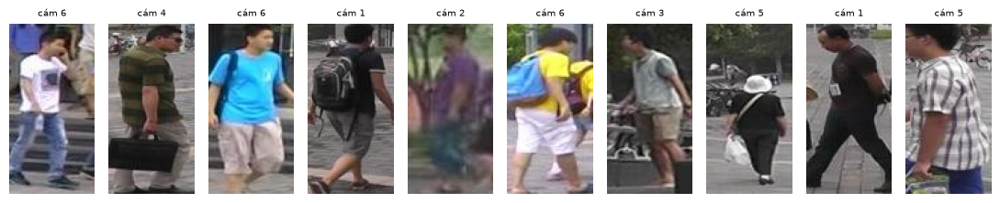

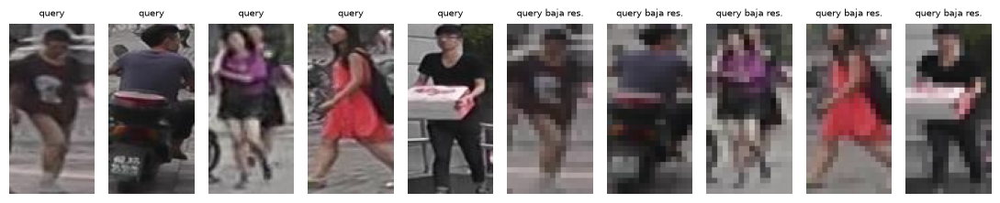

In [5]:
def show_grid(imgs_u8, titles=None, ncol=10, h=2.2, name='grid'):
    n = len(imgs_u8); nrow = math.ceil(n / ncol)
    fig, axes = plt.subplots(nrow, ncol, figsize=(ncol * h * 0.5, nrow * h))
    for i, ax in enumerate(np.atleast_1d(axes).ravel()):
        ax.axis('off')
        if i < n:
            ax.imshow(np.transpose(imgs_u8[i], (1, 2, 0)))
            if titles is not None: ax.set_title(titles[i], fontsize=7)
    plt.tight_layout(); finish(fig, name)

idx = np.arange(10)
show_grid(train['images'][idx], [f'cám {c}' for c in train['camera_ids'][idx]], name='02_training_ejemplos')
show_grid(np.concatenate([val['query/images'][:5], val['query/images_low_resolution'][:5].repeat(4, 2).repeat(4, 3)]),
          ['query'] * 5 + ['query baja res.'] * 5, name='02_query_vs_baja_res')

## 3. Preprocesamiento y augmentaciones

Las augmentaciones se ejecutan **por lotes en la GPU** (sin DataLoader), lo que acelera el entrenamiento y evita problemas de workers en Windows. Cada imagen genera dos vistas con pipelines asimétricos T y T′, como en BYOL:

1. **Baja resolución simulada** (p = 0.5): reducción ×2, ×3 o ×4 con bicúbica y antialias, y luego reescalado. El factor 4 reproduce las consultas de 32×16.
2. **Recorte suave + redimensionado a 256×128:** escala del recorte entre 0.8 y 1, proporción ancho/alto entre 0.4 y 0.6. Un recorte agresivo destruiría la alineación del cuerpo.
3. **Flip horizontal** (p = 0.5).
4. **Color jitter** (p = 0.8): brillo 0.4, contraste 0.4, saturación 0.2, tono 0.1.
5. **Escala de grises** (p = 0.2).
6. **Blur gaussiano:** p = 1.0 en T y p = 0.1 en T′.
7. **Solarización** (solo T′, p = 0.2).
8. **Normalización ImageNet.**
9. **Random erasing** (p = 0.5).

En evaluación solo se redimensiona a 256×128 y se normaliza. Las consultas de baja resolución (32×16) se suben directamente a 256×128.

In [6]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def to_float(x_u8):
    return x_u8.float().div(255.0)

def normalize(x):
    return (x - MEAN.to(x.device)) / STD.to(x.device)

def resize(x, h, w):
    return F.interpolate(x, size=(h, w), mode='bilinear', align_corners=False)

def prep_eval(x_u8, h, w):
    return normalize(resize(to_float(x_u8), h, w))

def random_lowres(x, p, factors):
    B, _, H, W = x.shape
    out = x.clone()
    apply = torch.rand(B, device=x.device) < p
    choice = torch.randint(len(factors), (B,), device=x.device)
    for k, f in enumerate(factors):
        m = apply & (choice == k)
        if m.any():
            small = F.interpolate(x[m], size=(H // f, W // f), mode='bicubic', align_corners=False, antialias=True)
            out[m] = F.interpolate(small, size=(H, W), mode='bicubic', align_corners=False).clamp(0, 1)
    return out

def random_resized_crop(x, out_h, out_w, scale, ratio):
    """Recorte aleatorio por muestra + redimensionado en un solo paso con roi_align."""
    B, _, H, W = x.shape
    dev = x.device
    area = H * W * torch.empty(B, device=dev).uniform_(*scale)
    r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1])))  # ancho/alto
    w = torch.sqrt(area * r).clamp(max=W)
    h = torch.sqrt(area / r).clamp(max=H)
    x0 = torch.rand(B, device=dev) * (W - w)
    y0 = torch.rand(B, device=dev) * (H - h)
    boxes = torch.stack([torch.arange(B, device=dev, dtype=x.dtype), x0, y0, x0 + w, y0 + h], dim=1)
    return roi_align(x, boxes, output_size=(out_h, out_w), spatial_scale=1.0, sampling_ratio=2, aligned=True)

def random_flip(x, p=0.5):
    m = (torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p)
    return torch.where(m, x.flip(-1), x)

def _gray(x):
    return 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]

_RGB2YIQ = torch.tensor([[0.299, 0.587, 0.114], [0.596, -0.274, -0.322], [0.211, -0.523, 0.312]])
_YIQ2RGB = torch.linalg.inv(_RGB2YIQ)

def _hue_rotate(x, theta):
    """Rota el tono girando los canales de crominancia (I, Q) del espacio YIQ."""
    B = x.shape[0]
    c, s = torch.cos(theta), torch.sin(theta)
    R = torch.zeros(B, 3, 3, device=x.device)
    R[:, 0, 0] = 1; R[:, 1, 1] = c; R[:, 1, 2] = -s; R[:, 2, 1] = s; R[:, 2, 2] = c
    M = _YIQ2RGB.to(x.device) @ R @ _RGB2YIQ.to(x.device)
    return torch.einsum('bij,bjhw->bihw', M, x)

def color_jitter(x, p, b=0.4, c=0.4, s=0.2, h=0.1):
    B, dev = x.shape[0], x.device
    u = lambda a: torch.empty(B, 1, 1, 1, device=dev).uniform_(1 - a, 1 + a)
    y = x * u(b)                                             # brillo
    m = _gray(y).mean(dim=(2, 3), keepdim=True)
    y = (y - m) * u(c) + m                                   # contraste
    g = _gray(y)
    y = (y - g) * u(s) + g                                   # saturación
    y = _hue_rotate(y, torch.empty(B, device=dev).uniform_(-h, h) * 2 * math.pi)   # tono
    y = y.clamp(0, 1)
    apply = torch.rand(B, 1, 1, 1, device=dev) < p
    return torch.where(apply, y, x)

def random_grayscale(x, p):
    apply = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p
    return torch.where(apply, _gray(x).expand_as(x), x)

def gaussian_blur(x, p, sigma=(0.1, 2.0), k=13):
    B, C, H, W = x.shape
    m = torch.rand(B, device=x.device) < p
    if not m.any():
        return x
    xs = x[m]; n = xs.shape[0]
    s = torch.empty(n, device=x.device).uniform_(*sigma)
    r = torch.arange(k, device=x.device, dtype=x.dtype) - k // 2
    ker = torch.exp(-(r[None] ** 2) / (2 * s[:, None] ** 2))
    ker = (ker / ker.sum(1, keepdim=True)).repeat_interleave(C, 0)        # (n*C, k), un sigma por imagen
    y = xs.reshape(1, n * C, H, W)
    y = F.conv2d(F.pad(y, (k // 2, k // 2, 0, 0), mode='reflect'), ker.view(n * C, 1, 1, k), groups=n * C)
    y = F.conv2d(F.pad(y, (0, 0, k // 2, k // 2), mode='reflect'), ker.view(n * C, 1, k, 1), groups=n * C)
    out = x.clone(); out[m] = y.view(n, C, H, W)
    return out

def random_solarize(x, p, thr=0.5):
    apply = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p
    return torch.where(apply & (x >= thr), 1 - x, x)

def random_erasing(x, p, scale=(0.02, 0.33), ratio=(0.3, 3.3)):
    B, C, H, W = x.shape
    dev = x.device
    area = H * W * torch.empty(B, device=dev).uniform_(*scale)
    r = torch.exp(torch.empty(B, device=dev).uniform_(math.log(ratio[0]), math.log(ratio[1])))
    h = torch.sqrt(area * r).clamp(max=H); w = torch.sqrt(area / r).clamp(max=W)
    y0 = torch.rand(B, device=dev) * (H - h); x0 = torch.rand(B, device=dev) * (W - w)
    ys = torch.arange(H, device=dev).view(1, H, 1); xs = torch.arange(W, device=dev).view(1, 1, W)
    mask = ((ys >= y0.view(B, 1, 1)) & (ys < (y0 + h).view(B, 1, 1)) &
            (xs >= x0.view(B, 1, 1)) & (xs < (x0 + w).view(B, 1, 1)))
    mask = mask & (torch.rand(B, 1, 1, device=dev) < p)
    return x.masked_fill(mask.unsqueeze(1), 0.0)      # 0 = media tras normalizar

@torch.no_grad()
def augment(x_u8, cfg, view):
    """x_u8: (B,3,128,64) uint8 en DEVICE -> vista aumentada (B,3,img_h,img_w) normalizada."""
    x = to_float(x_u8)
    x = random_lowres(x, cfg['lowres_p'], cfg['lowres_factors'])
    x = random_resized_crop(x, cfg['img_h'], cfg['img_w'], (cfg['crop_min_scale'], 1.0), cfg['crop_ratio'])
    x = random_flip(x)
    x = color_jitter(x, 0.8)
    x = random_grayscale(x, 0.2)
    x = gaussian_blur(x, 1.0 if view == 1 else 0.1)
    if view == 2:
        x = random_solarize(x, 0.2)
    x = normalize(x)
    return random_erasing(x, cfg['erase_p'])

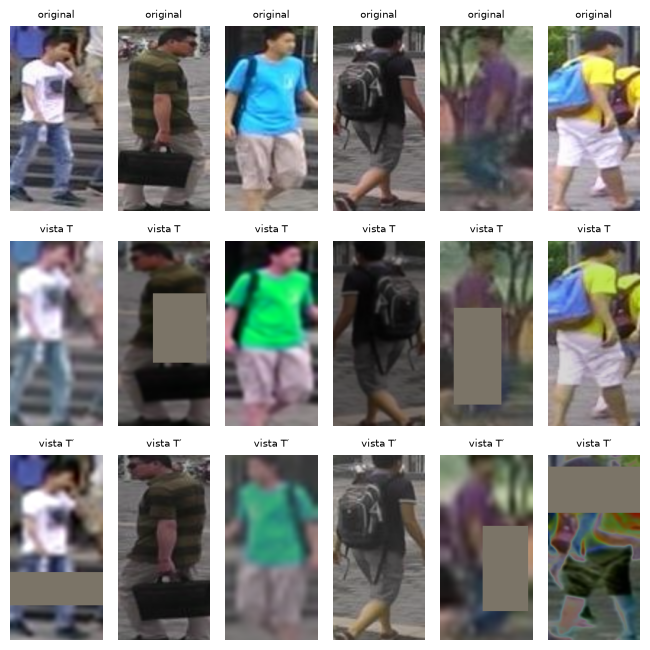

In [7]:
def denorm(x):
    return (x * STD.to(x.device) + MEAN.to(x.device)).clamp(0, 1)

xb = TRAIN_U8[:6].to(DEVICE)
v1, v2 = augment(xb, CFG, 1), augment(xb, CFG, 2)
vis = torch.cat([resize(to_float(xb), CFG['img_h'], CFG['img_w']), denorm(v1), denorm(v2)])
show_grid((vis.cpu().numpy() * 255).astype(np.uint8), ['original'] * 6 + ['vista T'] * 6 + ['vista T′'] * 6, ncol=6, name='03_vistas_aumentadas')

## 4. Modelo CO-BYOL

- **Online:** encoder f_θ (ResNet sin `fc`) → mapa local L ∈ ℝ^{B×2048×8×4} y global h = avgpool(L).
  - Rama global: proyector g¹ y predictor q¹ (MLP).
  - Rama local: proyector g² y predictor q² (conv 1×1, es decir, un MLP aplicado a cada posición).
- **Target:** copia EMA de f_θ, g¹ y g², sin predictores y sin gradientes.
- **Embedding de Re-ID:** h del encoder online, normalizado L2. Las cabezas solo se usan para entrenar.

**Extensión (4.1):** además de la ResNet50 preentrenada, el grupo implementó **RF-ResNet50**, la arquitectura del paper (Apéndice A), que se entrena desde cero. La cabeza de CO-BYOL es la misma; solo cambia el encoder y se añade el MLP con *skip* tras el avgpool, como en el paper.

### 4.1 Extensión: RF-ResNet50 (Apéndice A del paper)

Una ResNet50 estándar tiene un campo receptivo teórico de ~425 px en `layer4`, más grande que la propia imagen (256×128): cada vector "local" ya ve a toda la persona. RF-ResNet limita ese campo para que los vectores locales representen **partes**:

1. Las convoluciones 3×3 pasan a **1×1**, salvo la primera y la "del medio" de cada una de las 4 pilas de bloques.
2. Hiperparámetros `m` (MaxPool inicial) y strides de las pilas 2–4 controlan el campo receptivo. **RF99** = sin MaxPool y strides (2, 2, 2): RF teórico de 99 px (fórmula del Apéndice B, verificada abajo).
3. Un **MLP bottleneck con skip** tras el avgpool (en el paper, entre el pooling y los proyectores).
4. Un bloque extra en la pila 4 `(3, 4, 6, 4)` para igualar los parámetros de ResNet50 (paper: 21.4 M sin MLP, 23.7 M con MLP; se verifica abajo).

Con entrada 256×128, el stride total es 16 y el mapa local es **16×8 = 128 vectores** (vs 32 con ResNet50). No admite pesos de ImageNet: se entrena **desde cero**.

In [8]:
# ---------- RF-ResNet50 (Apéndice A del paper), implementación del grupo ----------
# m: MaxPool inicial; strides: stride del 1.er bloque de cada pila; blocks: nº de bloques por pila.
# Solo el 1.er bloque y el "del medio" de cada pila conservan la conv 3x3; el resto usa 1x1.
RF_ARCHS = {
    'rf39':  dict(m=False, strides=(1, 1, 1, 1), blocks=(3, 4, 6, 4)),
    'rf99':  dict(m=False, strides=(1, 2, 2, 2), blocks=(3, 4, 6, 4)),   # RF99-ResNet50 (el del paper)
    'rf115': dict(m=True,  strides=(1, 2, 1, 1), blocks=(3, 4, 6, 4)),
    'rf193': dict(m=True,  strides=(1, 2, 2, 2), blocks=(3, 4, 6, 4)),
}

def uses_3x3(b, n):
    return b == 0 or b == n // 2

def rf_theoretical(a):
    """Campo receptivo teórico (Apéndice B): cada conv de kernel k suma (k-1) * 'salto' acumulado."""
    rf, jump = 7, 2                          # conv1 7x7, stride 2
    if a['m']:
        rf += 2 * jump; jump *= 2            # MaxPool 3x3, stride 2
    for n, s in zip(a['blocks'], a['strides']):
        for b in range(n):
            if uses_3x3(b, n):
                rf += 2 * jump
                if b == 0:
                    jump *= s
    return rf

class RFBottleneck(nn.Module):
    def __init__(self, cin, mid, cout, k, stride):
        super().__init__()
        self.f = nn.Sequential(
            nn.Conv2d(cin, mid, 1, bias=False), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, mid, k, stride, k // 2, bias=False), nn.BatchNorm2d(mid), nn.ReLU(inplace=True),
            nn.Conv2d(mid, cout, 1, bias=False), nn.BatchNorm2d(cout))
        self.sc = None if (stride == 1 and cin == cout) else nn.Sequential(
            nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        return F.relu(self.f(x) + (x if self.sc is None else self.sc(x)))

def make_rf_backbone(a):
    layers = [nn.Conv2d(3, 64, 7, 2, 3, bias=False), nn.BatchNorm2d(64), nn.ReLU(inplace=True)]
    if a['m']:
        layers.append(nn.MaxPool2d(3, 2, 1))
    cin = 64
    for n, s, mid in zip(a['blocks'], a['strides'], (64, 128, 256, 512)):
        for b in range(n):
            layers.append(RFBottleneck(cin, mid, mid * 4, 3 if uses_3x3(b, n) else 1, s if b == 0 else 1))
            cin = mid * 4
    return nn.Sequential(*layers)

class FCBottleneck(nn.Module):
    """MLP tras el avgpool de RF-ResNet: bloque bottleneck totalmente conectado, con skip (Apéndice A)."""
    def __init__(self, d=2048, mid=512):
        super().__init__()
        self.f = nn.Sequential(nn.Linear(d, mid, bias=False), nn.BatchNorm1d(mid), nn.ReLU(inplace=True),
                               nn.Linear(mid, mid, bias=False), nn.BatchNorm1d(mid), nn.ReLU(inplace=True),
                               nn.Linear(mid, d, bias=False), nn.BatchNorm1d(d))
    def forward(self, x):
        return F.relu(x + self.f(x))

### 4.2 Ensamblado de CO-BYOL (encoder, MLP opcional, cabezas global y local)

In [9]:
def build_backbone(arch, pretrained, last_stride=2):
    if arch in RF_ARCHS:       # RF-ResNet50 del paper: siempre desde cero (no hay pesos preentrenados)
        return make_rf_backbone(RF_ARCHS[arch]), 2048
    if arch == 'resnet50':
        net = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None)
    elif arch == 'resnet18':
        net = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
    else:
        raise ValueError(arch)
    if last_stride == 1:     # opción típica en Re-ID: mapa 16x8 en vez de 8x4
        blk = net.layer4[0]
        for conv in [blk.conv1, blk.conv2]:
            conv.stride = (1, 1)
        blk.downsample[0].stride = (1, 1)
    feat_dim = net.fc.in_features
    body = nn.Sequential(net.conv1, net.bn1, net.relu, net.maxpool, net.layer1, net.layer2, net.layer3, net.layer4)
    return body, feat_dim

class MLPHead(nn.Module):
    def __init__(self, d_in, d_hid, d_out):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_in, d_hid), nn.BatchNorm1d(d_hid), nn.ReLU(inplace=True), nn.Linear(d_hid, d_out))
    def forward(self, x):
        return self.net(x)

class ConvHead(nn.Module):
    """Cabeza local: equivale a un MLP aplicado de forma independiente a cada posición del mapa."""
    def __init__(self, d_in, d_hid, d_out):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(d_in, d_hid, 1), nn.BatchNorm2d(d_hid), nn.ReLU(inplace=True), nn.Conv2d(d_hid, d_out, 1))
    def forward(self, x):
        return self.net(x)

class COBYOL(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.encoder, d = build_backbone(cfg['arch'], cfg['pretrained'], cfg['last_stride'])
        hid, out = cfg['proj_hidden'], cfg['proj_dim']
        # RF-ResNet: MLP bottleneck con skip tras el avgpool (Apéndice A); ResNet estándar: identidad
        self.neck = FCBottleneck(d) if cfg['arch'] in RF_ARCHS else nn.Identity()
        self.g1, self.q1 = MLPHead(d, hid, out), MLPHead(out, hid, out)      # global
        self.g2, self.q2 = ConvHead(d, hid, out), ConvHead(out, hid, out)    # local (CO-SSL)
        self.t_encoder = copy.deepcopy(self.encoder)
        self.t_g1, self.t_g2 = copy.deepcopy(self.g1), copy.deepcopy(self.g2)
        self.t_neck = copy.deepcopy(self.neck)
        for p in self.target_params():
            p.requires_grad = False

    def online_pairs(self):
        return [(self.encoder, self.t_encoder), (self.neck, self.t_neck), (self.g1, self.t_g1), (self.g2, self.t_g2)]

    def target_params(self):
        return [p for _, t in self.online_pairs() for p in t.parameters()]

    def online(self, x, use_local):
        L = self.encoder(x)                     # (B, D, n, m)
        h = self.neck(L.mean(dim=(2, 3)))       # (B, D)
        out = {'p_g': self.q1(self.g1(h))}
        if use_local:
            out['p_l'] = self.q2(self.g2(L)).flatten(2)        # (B, out, n*m)
        return out

    @torch.no_grad()
    def target(self, x, use_local):
        L = self.t_encoder(x)
        out = {'z_g': self.t_g1(self.t_neck(L.mean(dim=(2, 3))))}
        if use_local:
            out['z_l'] = self.t_g2(L).flatten(2)
        return out

    @torch.no_grad()
    def update_target(self, tau):
        for o, t in self.online_pairs():
            for po, pt in zip(o.parameters(), t.parameters()):
                pt.mul_(tau).add_(po.detach(), alpha=1 - tau)

m = COBYOL(CFG)
n_par = lambda mod: sum(p.numel() for p in mod.parameters()) / 1e6
print(f'encoder {n_par(m.encoder):.1f}M | neck {n_par(m.neck):.1f}M | g1+q1 {n_par(m.g1) + n_par(m.q1):.1f}M | g2+q2 (local) {n_par(m.g2) + n_par(m.q2):.1f}M')
with torch.no_grad():
    L = m.encoder.eval()(torch.zeros(2, 3, CFG['img_h'], CFG['img_w']))
print('Mapa local:', tuple(L.shape), '-> n^2 =', L.shape[2] * L.shape[3], 'vectores locales por vista')
del m, L

encoder 23.5M | neck 0.0M | g1+q1 11.6M | g2+q2 (local) 11.6M


Mapa local: (2, 2048, 8, 4) -> n^2 = 32 vectores locales por vista


In [10]:
# Verificación de RF-ResNet50 contra las cifras del paper
for k, esperado in [('rf39', 39), ('rf99', 99), ('rf115', 115)]:
    assert rf_theoretical(RF_ARCHS[k]) == esperado, (k, rf_theoretical(RF_ARCHS[k]))
print({k: rf_theoretical(a) for k, a in RF_ARCHS.items()}, '(paper: 39, 99, 115, 193)')

_bb = make_rf_backbone(RF_ARCHS['rf99'])
p_bb = sum(p.numel() for p in _bb.parameters()) / 1e6
p_mlp = sum(p.numel() for p in FCBottleneck(2048).parameters()) / 1e6
print(f'RF99-ResNet50: {p_bb:.1f}M sin MLP | {p_bb + p_mlp:.1f}M con MLP (paper: 21.4M y 23.7M; ResNet50 estándar: 23.5M)')
assert abs(p_bb - 21.4) < 0.1 and abs(p_bb + p_mlp - 23.7) < 0.1
with torch.no_grad():
    _L = _bb.eval()(torch.zeros(2, 3, CFG['img_h'], CFG['img_w']))
print('Mapa local RF99:', tuple(_L.shape), '-> n^2 =', _L.shape[2] * _L.shape[3], 'vectores locales por vista')
del _bb, _L

{'rf39': 39, 'rf99': 99, 'rf115': 115, 'rf193': 195} (paper: 39, 99, 115, 193)
RF99-ResNet50: 21.4M sin MLP | 23.7M con MLP (paper: 21.4M y 23.7M; ResNet50 estándar: 23.5M)


Mapa local RF99: (2, 2048, 16, 8) -> n^2 = 128 vectores locales por vista


## 5. Pérdida CO-BYOL (núcleo de la propuesta)

$$\mathcal{L}_g = 2 - 2\cos(p_g, \mathrm{sg}(z'_g))$$

$$\mathcal{L}_l = \frac{1}{n^2}\sum_{i=1}^{n^2}\Big[(2 - 2\cos(p_l^i, \mathrm{sg}(z'_g))) + (2 - 2\cos(p_g, \mathrm{sg}(z'^{\,i}_l)))\Big]$$

$$\mathcal{L} = \mathcal{L}_g(v,v') + \mathcal{L}_g(v',v) + w_s\,[\mathcal{L}_l(v,v') + \mathcal{L}_l(v',v)]$$

Se usa 2 − 2cos en lugar de −2cos (Ec. 1 del paper). La diferencia es una constante, así que los gradientes son idénticos. Con w_s = 0 se recupera exactamente BYOL, que es nuestro **baseline**.

In [11]:
def byol_loss(p, z):
    """p, z: (B, D) o (B, D, N). Coseno sobre la dimensión de características (dim=1)."""
    return 2 - 2 * F.cosine_similarity(p.float(), z.detach().float(), dim=1)

def co_byol_loss(on1, on2, tg1, tg2, w_s, n_local=None):
    """on*: salidas online {'p_g', 'p_l'}; tg*: salidas target {'z_g', 'z_l'} de la OTRA vista."""
    def lg(on, tg):
        return byol_loss(on['p_g'], tg['z_g']).mean()

    def ll(on, tg):
        p_l, z_l = on['p_l'], tg['z_l']                      # (B, D, N)
        if n_local is not None and n_local < p_l.shape[-1]:  # ablación: menos pares por imagen
            idx = torch.randperm(p_l.shape[-1], device=p_l.device)[:n_local]
            p_l, z_l = p_l[..., idx], z_l[..., idx]
        a = byol_loss(p_l, tg['z_g'].unsqueeze(-1))          # local online  -> global target
        b = byol_loss(on['p_g'].unsqueeze(-1), z_l)          # global online -> local target
        return (a + b).mean()                                # promedio sobre B y N

    L_g = lg(on1, tg2) + lg(on2, tg1)
    if w_s == 0:
        return L_g, L_g.detach(), torch.zeros((), device=L_g.device)
    L_l = ll(on1, tg2) + ll(on2, tg1)
    return L_g + w_s * L_l, L_g.detach(), L_l.detach()

In [12]:
# Tests unitarios de la pérdida
torch.manual_seed(0)
B, D, N = 4, 8, 6
mk = lambda: {'p_g': torch.randn(B, D, requires_grad=True), 'p_l': torch.randn(B, D, N, requires_grad=True)}
mt = lambda: {'z_g': torch.randn(B, D), 'z_l': torch.randn(B, D, N)}
on1, on2, tg1, tg2 = mk(), mk(), mt(), mt()

# 1) Con w_s = 0 es exactamente la pérdida simétrica de BYOL
loss0, _, _ = co_byol_loss(on1, on2, tg1, tg2, w_s=0.0)
ref = (2 - 2 * F.cosine_similarity(on1['p_g'], tg2['z_g'])).mean() + (2 - 2 * F.cosine_similarity(on2['p_g'], tg1['z_g'])).mean()
assert torch.allclose(loss0, ref), 'w_s=0 debería ser BYOL'

# 2) El término local coincide con un bucle explícito sobre las n^2 posiciones
def ll_loop(on, tg):
    s = 0
    for i in range(N):
        s += (2 - 2 * F.cosine_similarity(on['p_l'][..., i], tg['z_g'])).mean()
        s += (2 - 2 * F.cosine_similarity(on['p_g'], tg['z_l'][..., i])).mean()
    return s / N
loss1, Lg, Ll = co_byol_loss(on1, on2, tg1, tg2, w_s=1.0)
assert torch.allclose(Ll, ll_loop(on1, tg2) + ll_loop(on2, tg1), atol=1e-5), 'L_l vectorizada != bucle'

# 3) Rango: cada término de 2-2cos está en [0, 4]
assert 0 <= Lg.item() <= 8 and 0 <= Ll.item() <= 16

# 4) Los gradientes no llegan al target (stop-gradient) en el modelo real
mm = COBYOL({**CFG, 'arch': 'resnet18', 'pretrained': False, 'proj_hidden': 64, 'proj_dim': 32})
x = torch.randn(4, 3, 64, 32)
o1, o2 = mm.online(x, True), mm.online(x.flip(-1), True)
t1, t2 = mm.target(x, True), mm.target(x.flip(-1), True)
l, _, _ = co_byol_loss(o1, o2, t1, t2, w_s=0.5)
l.backward()
assert all(p.grad is None for p in mm.target_params()), 'el target no debe recibir gradiente'
assert mm.g2.net[0].weight.grad is not None, 'la cabeza local debe recibir gradiente'
print('Todos los tests de la pérdida pasan ✔')
del mm

Todos los tests de la pérdida pasan ✔


## 6. Entrenamiento

- **Optimizador:** AdamW con warmup lineal y luego coseno. El backbone preentrenado usa un lr menor (`backbone_lr_mult`).
- **Target:** EMA con τ de 0.99 a 1, con schedule coseno.
- **Precisión:** AMP fp16 en GPU.
- **Registro:** se guardan L_g y L_l por separado, y cada `eval_every` épocas se mide el mAP en validación (ambas condiciones) y se guarda el mejor encoder según el mAP original.
- **Reanudación:** si el job de KHIPU alcanza su límite de tiempo (`LAB3_TIME_LIMIT_H`), o si se corta la sesión de OnDemand o de Colab, se guarda `last.pt`. Al volver a ejecutar, la corrida continúa desde ahí. Una corrida terminada (`done.json`) se salta.

In [13]:
def lr_at(step, total, warmup, base):
    if step < warmup:
        return base * (step + 1) / warmup
    return base * 0.5 * (1 + math.cos(math.pi * (step - warmup) / max(1, total - warmup)))

def train_run(name, cfg, images_u8, val_data=None):
    run_dir = OUT_DIR / name
    run_dir.mkdir(parents=True, exist_ok=True)
    if (run_dir / 'done.json').exists():
        print(f'[{name}] ya terminada, se carga el resumen.')
        return json.loads((run_dir / 'done.json').read_text())

    seed_everything(cfg['seed'])
    use_local = cfg['w_s'] > 0
    model = COBYOL(cfg).to(DEVICE)
    enc_params = list(model.encoder.parameters())
    head_params = [p for mod in [model.neck, model.g1, model.q1] + ([model.g2, model.q2] if use_local else []) for p in mod.parameters()]
    opt = torch.optim.AdamW([{'params': enc_params, 'lr_mult': cfg['backbone_lr_mult']},
                             {'params': head_params, 'lr_mult': 1.0}], lr=cfg['lr'], weight_decay=cfg['weight_decay'])
    use_amp = cfg['amp'] and DEVICE.type == 'cuda'
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

    X = images_u8.to(DEVICE)
    N, bs = len(X), cfg['batch_size']
    spe = N // bs
    total, warmup = cfg['epochs'] * spe, cfg['warmup_epochs'] * spe
    hist = {'epoch': [], 'L_g': [], 'L_l': [], 'sec': [], 'val': []}
    best_map, best_epoch, start = -1.0, None, 0

    ck = run_dir / 'last.pt'
    if ck.exists():
        st = torch.load(ck, map_location=DEVICE, weights_only=False)
        model.load_state_dict(st['model']); opt.load_state_dict(st['opt']); scaler.load_state_dict(st['scaler'])
        hist, best_map, best_epoch, start = st['hist'], st['best_map'], st['best_epoch'], st['epoch'] + 1
        print(f'[{name}] reanudando desde la época {start}')

    print(f'[{name}] {N} imágenes, {spe} iteraciones/época, arch={cfg["arch"]}, w_s={cfg["w_s"]}, recorte mín.={cfg["crop_min_scale"]}')
    for epoch in range(start, cfg['epochs']):
        model.train()
        t0 = time.time(); sum_g = sum_l = 0.0
        perm = torch.randperm(N, device=DEVICE)
        for it in range(spe):
            step = epoch * spe + it
            xb = X[perm[it * bs:(it + 1) * bs]]
            v1, v2 = augment(xb, cfg, 1), augment(xb, cfg, 2)
            lr = lr_at(step, total, warmup, cfg['lr'])
            for g in opt.param_groups:
                g['lr'] = lr * g['lr_mult']
            with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                on1, on2 = model.online(v1, use_local), model.online(v2, use_local)
                tg1, tg2 = model.target(v1, use_local), model.target(v2, use_local)
                loss, Lg, Ll = co_byol_loss(on1, on2, tg1, tg2, cfg['w_s'], cfg['n_local'])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            tau = 1 - (1 - cfg['tau_base']) * (math.cos(math.pi * step / total) + 1) / 2
            model.update_target(tau)
            sum_g += Lg.item(); sum_l += Ll.item()
        if DEVICE.type == 'cuda':
            torch.cuda.synchronize()
        sec = time.time() - t0
        hist['epoch'].append(epoch + 1); hist['L_g'].append(sum_g / spe); hist['L_l'].append(sum_l / spe); hist['sec'].append(sec)
        msg = f'[{name}] época {epoch + 1}/{cfg["epochs"]}  L_g={sum_g / spe:.4f}  L_l={sum_l / spe:.4f}  {sec:.0f}s'

        last = epoch + 1 == cfg['epochs']
        if (epoch + 1) % cfg['eval_every'] == 0 or last:
            if val_data is not None:
                r = evaluate_both(model.encoder, val_data, cfg)
                hist['val'].append({'epoch': epoch + 1, **flat_metrics(r)})
                msg += f"  | val mAP={r['orig']['mAP']:.2f}  R1={r['orig']['R1']:.2f}  mAP baja={r['low']['mAP']:.2f}"
                if r['orig']['mAP'] > best_map:
                    best_map, best_epoch = r['orig']['mAP'], epoch + 1
                    torch.save(model.encoder.state_dict(), run_dir / 'best_encoder.pt')
            if not last:
                torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                            'hist': hist, 'best_map': best_map, 'best_epoch': best_epoch, 'epoch': epoch}, ck)
        print(msg)
        if time.time() > DEADLINE and epoch + 1 < cfg['epochs']:
            torch.save({'model': model.state_dict(), 'opt': opt.state_dict(), 'scaler': scaler.state_dict(),
                        'hist': hist, 'best_map': best_map, 'best_epoch': best_epoch, 'epoch': epoch}, ck)
            raise SystemExit(f'[{name}] Límite de tiempo del job alcanzado: checkpoint guardado en la época {epoch + 1}. '
                             'Vuelve a enviar el mismo job para continuar.')

    torch.save(model.encoder.state_dict(), run_dir / 'last_encoder.pt')
    summary = {'name': name, 'cfg': {k: (list(v) if isinstance(v, tuple) else v) for k, v in cfg.items()},
               'hist': hist, 'best_epoch': best_epoch, 'best_val_mAP': best_map,
               'sec_per_epoch': float(np.mean(hist['sec']))}
    (run_dir / 'done.json').write_text(json.dumps(summary, indent=1))
    if ck.exists():
        ck.unlink()     # libera espacio en Drive
    del model, opt, X
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return summary

def load_encoder(name, cfg, which='best'):
    done = OUT_DIR / name / 'done.json'
    rc = json.loads(done.read_text())['cfg'] if done.exists() else cfg      # cada corrida recuerda su arquitectura
    enc, _ = build_backbone(rc['arch'], False, rc['last_stride'])
    enc.load_state_dict(torch.load(OUT_DIR / name / f'{which}_encoder.pt', map_location='cpu'))
    return enc.to(DEVICE).eval()

## 7. Evaluación (protocolo Market-1501)

1. **Embedding:** avgpool del encoder online, promediado con la imagen volteada (`flip_test`, igual para todos los modelos) y normalizado L2.
2. **Similitud:** coseno, que es el producto punto entre vectores normalizados.
3. **Filtrado por query:** se excluyen de la galería (a) las imágenes de la **misma persona en la misma cámara** y (b) las imágenes *junk* (id −1). Las de id 0 (distractores) cuentan como negativos.
4. **Métricas:** AP por query → mAP, y CMC → Rank-1/5/10. Las queries sin ningún positivo válido se omiten.

In [14]:
@torch.no_grad()
def extract(encoder, imgs_u8, cfg, bs=256):
    encoder.eval()
    use_amp = cfg['amp'] and DEVICE.type == 'cuda'
    feats = []
    for i in range(0, len(imgs_u8), bs):
        x = prep_eval(torch.as_tensor(imgs_u8[i:i + bs]).to(DEVICE), cfg['img_h'], cfg['img_w'])
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
            f = encoder(x).mean(dim=(2, 3)).float()
            if cfg['flip_test']:
                f = f + encoder(x.flip(-1)).mean(dim=(2, 3)).float()
        feats.append(F.normalize(f, dim=1).cpu())
    return torch.cat(feats)

def compute_metrics(sim, q_pids, q_cams, g_pids, g_cams, topk=10, chunk=256):
    """sim: (Q, G) tensor de similitudes. Devuelve métricas, AP por query y top-k filtrado por query."""
    sim = torch.as_tensor(sim)
    Q = sim.shape[0]
    aps = np.full(Q, np.nan); first_hit = np.full(Q, -1); tops = np.full((Q, topk), -1, dtype=np.int64)
    for s in range(0, Q, chunk):
        order = torch.argsort(sim[s:s + chunk].to(DEVICE), dim=1, descending=True).cpu().numpy()
        for j, o in enumerate(order):
            i = s + j
            gp, gc = g_pids[o], g_cams[o]
            keep = ~(((gp == q_pids[i]) & (gc == q_cams[i])) | (gp == -1))
            o_k = o[keep]
            match = gp[keep] == q_pids[i]
            tops[i, :min(topk, len(o_k))] = o_k[:topk]
            if not match.any():
                continue
            pos = np.flatnonzero(match)
            aps[i] = np.mean(np.arange(1, len(pos) + 1) / (pos + 1))
            first_hit[i] = pos[0]
    valid = ~np.isnan(aps)
    fh = first_hit[valid]
    m = {'mAP': 100 * aps[valid].mean(), 'R1': 100 * (fh < 1).mean(), 'R5': 100 * (fh < 5).mean(),
         'R10': 100 * (fh < 10).mean(), 'n_queries': int(valid.sum())}
    return m, aps, tops

def evaluate_both(encoder, data, cfg, return_details=False):
    """Mismo modelo, dos condiciones: queries originales y queries de baja resolución (galería original)."""
    gf = extract(encoder, data['gallery/images'], cfg)
    out = {}
    for cond, key in [('orig', 'query/images'), ('low', 'query/images_low_resolution')]:
        qf = extract(encoder, data[key], cfg)
        m, aps, tops = compute_metrics(qf @ gf.T, data['query/person_ids'], data['query/camera_ids'],
                                       data['gallery/person_ids'], data['gallery/camera_ids'])
        out[cond] = m
        if return_details:
            out[cond + '_aps'], out[cond + '_tops'] = aps, tops
    out['delta_mAP'] = out['orig']['mAP'] - out['low']['mAP']
    return out

def flat_metrics(r):
    d = {f'{k}_orig': v for k, v in r['orig'].items() if k != 'n_queries'}
    d.update({f'{k}_low': v for k, v in r['low'].items() if k != 'n_queries'})
    d['delta_mAP'] = r['delta_mAP']
    return d

In [15]:
# Test de juguete calculado a mano
# Query: persona 1, cámara 1. Galería ordenada por similitud:
#  0.99 p1/c1 (misma cámara -> excluida) | 0.90 p2 (negativo) | 0.85 p-1 (junk -> excluida) | 0.80 p1/c2 | 0.70 p1/c3
# Ranking filtrado: [neg, pos, pos] -> AP = (1/2 + 2/3)/2 = 0.5833, Rank-1 = 0, Rank-5 = 1
sim = torch.tensor([[0.99, 0.90, 0.80, 0.85, 0.70]])
m, aps, tops = compute_metrics(sim, np.array([1]), np.array([1]), np.array([1, 2, 1, -1, 1]), np.array([1, 2, 2, 3, 3]))
assert abs(m['mAP'] - 58.333) < 1e-2 and m['R1'] == 0 and m['R5'] == 100, m
assert tops[0, :3].tolist() == [1, 2, 4]
print('Test de evaluación correcto ✔', m)

Test de evaluación correcto ✔ {'mAP': np.float64(58.33333333333333), 'R1': np.float64(0.0), 'R5': np.float64(100.0), 'R10': np.float64(100.0), 'n_queries': 1}


## 8. Experimentos en validación

| # | Modelo | w_s | Recorte mínimo | Propósito |
|---|---|---|---|---|
| R0 | ImageNet R50 sin SSL | — | — | Referencia mínima |
| R1 | **BYOL (baseline)** | 0 | 0.8 | Comparación principal |
| R2–R4 | CO-BYOL | 0.2 / 0.5 / 1.0 | 0.8 | Selección de w_s |
| R5 | BYOL | 0 | 0.2 | Ablación del recorte |
| R6 | CO-BYOL (mejor w_s) | mejor | 0.2 | Ablación del recorte |
| R9 | BYOL con **RF99-ResNet50 desde cero** | 0 | 0.8 | Arquitectura del paper, sin pérdida local |
| R10 | **CO-BYOL con RF99-ResNet50 desde cero** | 0.5 | 0.8 | Método completo del paper (w_s = 0.5, Tabla 7) |

Las 100 queries de validación son pocas: diferencias menores a unos 2 puntos de mAP pueden ser ruido.

R9 y R10 (`LAB3_RF=1`) comparten arquitectura, datos y presupuesto de épocas: su diferencia aísla el aporte de la pérdida local-global. Se evalúan con el avgpool del encoder (variante *RF99-b* de la Tabla 6 del paper).

In [16]:
R0 = evaluate_both(build_backbone(CFG['arch'], CFG['pretrained'], CFG['last_stride'])[0].to(DEVICE), val, CFG)
print('R0 ImageNet sin SSL:', {k: round(v, 2) for k, v in flat_metrics(R0).items()})

R0 ImageNet sin SSL: {'mAP_orig': np.float64(10.41), 'R1_orig': np.float64(20.0), 'R5_orig': np.float64(38.0), 'R10_orig': np.float64(46.0), 'mAP_low': np.float64(5.29), 'R1_low': np.float64(7.0), 'R5_low': np.float64(18.0), 'R10_low': np.float64(29.0), 'delta_mAP': np.float64(5.12)}


In [17]:
EXPERIMENTS = {
    'R1_byol':          dict(w_s=0.0),
    'R2_cobyol_ws0.2':  dict(w_s=0.2),
    'R3_cobyol_ws0.5':  dict(w_s=0.5),
    'R4_cobyol_ws1.0':  dict(w_s=1.0),
    'R5_byol_crop0.2':  dict(w_s=0.0, crop_min_scale=0.2),
}
# --- Extensión fiel al paper: RF99-ResNet50 desde cero (sin pesos de ImageNet) ---
RF_BASE = dict(arch='rf99', pretrained=False, backbone_lr_mult=1.0, epochs=EPOCHS_RF,
               batch_size=min(CFG['batch_size'], BATCH_RF))
RF_EXPERIMENTS = {
    'R9_byol_rf99':     dict(RF_BASE, w_s=0.0),
    'R10_cobyol_rf99':  dict(RF_BASE, w_s=0.5),   # w_s = 0.5: mejor valor del paper (Tabla 7); no se barre por costo
}
ALL_EXPERIMENTS = {**EXPERIMENTS, **RF_EXPERIMENTS}

TO_RUN = list(EXPERIMENTS) + (list(RF_EXPERIMENTS) if USE_RF else [])
if env('LAB3_TO_RUN'):              # p. ej. LAB3_TO_RUN=R1_byol:R2_cobyol_ws0.2 (repartir entre integrantes)
    TO_RUN = [n for n in env('LAB3_TO_RUN').split(':') if n]
    assert all(n in ALL_EXPERIMENTS for n in TO_RUN), f'Nombres válidos: {list(ALL_EXPERIMENTS)}'
if SMOKE_TEST:
    TO_RUN = ['R1_byol', 'R3_cobyol_ws0.5'] + (list(RF_EXPERIMENTS) if USE_RF else [])
print('Corridas a entrenar en esta ejecución:', TO_RUN)

SUMMARIES = {}
for name in TO_RUN:
    SUMMARIES[name] = train_run(name, {**CFG, **ALL_EXPERIMENTS[name]}, TRAIN_U8, val)

if TRAIN_ONLY:
    print('TRAIN_ONLY=1: entrenamiento terminado para', TO_RUN, '-> fin de la ejecución.')
    sys.exit(0)

Corridas a entrenar en esta ejecución: ['R1_byol', 'R2_cobyol_ws0.2', 'R3_cobyol_ws0.5', 'R4_cobyol_ws1.0', 'R5_byol_crop0.2']
[R1_byol] ya terminada, se carga el resumen.
[R2_cobyol_ws0.2] ya terminada, se carga el resumen.


[R3_cobyol_ws0.5] 11043 imágenes, 345 iteraciones/época, arch=resnet50, w_s=0.5, recorte mín.=0.8


[R3_cobyol_ws0.5] época 1/50  L_g=2.3445  L_l=5.3968  98s


[R3_cobyol_ws0.5] época 2/50  L_g=1.3490  L_l=4.3608  85s


[R3_cobyol_ws0.5] época 3/50  L_g=0.7866  L_l=3.6118  86s


[R3_cobyol_ws0.5] época 4/50  L_g=0.6632  L_l=3.2367  84s


[R3_cobyol_ws0.5] época 5/50  L_g=0.6233  L_l=3.0732  85s  | val mAP=4.02  R1=7.00  mAP baja=3.62


[R3_cobyol_ws0.5] época 6/50  L_g=0.5860  L_l=2.9476  85s


[R3_cobyol_ws0.5] época 7/50  L_g=0.5694  L_l=2.8811  86s


[R3_cobyol_ws0.5] época 8/50  L_g=0.5567  L_l=2.8195  72s


[R3_cobyol_ws0.5] época 9/50  L_g=0.5494  L_l=2.7807  86s


[R3_cobyol_ws0.5] época 10/50  L_g=0.5419  L_l=2.7527  85s  | val mAP=4.46  R1=10.00  mAP baja=4.66


[R3_cobyol_ws0.5] época 11/50  L_g=0.5369  L_l=2.7252  86s


[R3_cobyol_ws0.5] época 12/50  L_g=0.5332  L_l=2.7123  85s


[R3_cobyol_ws0.5] época 13/50  L_g=0.5305  L_l=2.6879  86s


[R3_cobyol_ws0.5] época 14/50  L_g=0.5273  L_l=2.6707  85s


[R3_cobyol_ws0.5] época 15/50  L_g=0.5283  L_l=2.6608  86s  | val mAP=5.21  R1=10.00  mAP baja=4.89


[R3_cobyol_ws0.5] época 16/50  L_g=0.5266  L_l=2.6496  84s


[R3_cobyol_ws0.5] época 17/50  L_g=0.5249  L_l=2.6323  76s


[R3_cobyol_ws0.5] época 18/50  L_g=0.5199  L_l=2.6131  85s


[R3_cobyol_ws0.5] época 19/50  L_g=0.5208  L_l=2.6066  86s


[R3_cobyol_ws0.5] época 20/50  L_g=0.5167  L_l=2.5915  85s  | val mAP=5.32  R1=12.00  mAP baja=4.96


[R3_cobyol_ws0.5] época 21/50  L_g=0.5149  L_l=2.5792  85s


[R3_cobyol_ws0.5] época 22/50  L_g=0.5155  L_l=2.5756  86s


[R3_cobyol_ws0.5] época 23/50  L_g=0.5105  L_l=2.5673  85s


[R3_cobyol_ws0.5] época 24/50  L_g=0.5051  L_l=2.5510  86s


[R3_cobyol_ws0.5] época 25/50  L_g=0.5041  L_l=2.5456  75s  | val mAP=5.49  R1=13.00  mAP baja=5.04


[R3_cobyol_ws0.5] época 26/50  L_g=0.5025  L_l=2.5358  86s


[R3_cobyol_ws0.5] época 27/50  L_g=0.5014  L_l=2.5276  85s


[R3_cobyol_ws0.5] época 28/50  L_g=0.4959  L_l=2.5119  86s


[R3_cobyol_ws0.5] época 29/50  L_g=0.4947  L_l=2.5026  85s


[R3_cobyol_ws0.5] época 30/50  L_g=0.4933  L_l=2.4950  86s  | val mAP=5.67  R1=11.00  mAP baja=5.22


[R3_cobyol_ws0.5] época 31/50  L_g=0.4900  L_l=2.4869  85s


[R3_cobyol_ws0.5] época 32/50  L_g=0.4891  L_l=2.4812  86s


[R3_cobyol_ws0.5] época 33/50  L_g=0.4865  L_l=2.4726  85s


[R3_cobyol_ws0.5] época 34/50  L_g=0.4850  L_l=2.4690  76s


[R3_cobyol_ws0.5] época 35/50  L_g=0.4830  L_l=2.4640  85s  | val mAP=5.62  R1=11.00  mAP baja=5.28


[R3_cobyol_ws0.5] época 36/50  L_g=0.4813  L_l=2.4603  86s


[R3_cobyol_ws0.5] época 37/50  L_g=0.4794  L_l=2.4537  85s


[R3_cobyol_ws0.5] época 38/50  L_g=0.4785  L_l=2.4490  85s


[R3_cobyol_ws0.5] época 39/50  L_g=0.4776  L_l=2.4453  84s


[R3_cobyol_ws0.5] época 40/50  L_g=0.4772  L_l=2.4439  86s  | val mAP=5.78  R1=12.00  mAP baja=5.35


[R3_cobyol_ws0.5] época 41/50  L_g=0.4760  L_l=2.4407  85s


[R3_cobyol_ws0.5] época 42/50  L_g=0.4739  L_l=2.4352  72s


[R3_cobyol_ws0.5] época 43/50  L_g=0.4750  L_l=2.4358  78s


[R3_cobyol_ws0.5] época 44/50  L_g=0.4734  L_l=2.4322  86s


[R3_cobyol_ws0.5] época 45/50  L_g=0.4727  L_l=2.4303  85s  | val mAP=5.80  R1=12.00  mAP baja=5.31


[R3_cobyol_ws0.5] época 46/50  L_g=0.4726  L_l=2.4300  86s


[R3_cobyol_ws0.5] época 47/50  L_g=0.4737  L_l=2.4317  85s


[R3_cobyol_ws0.5] época 48/50  L_g=0.4722  L_l=2.4301  86s


[R3_cobyol_ws0.5] época 49/50  L_g=0.4718  L_l=2.4269  85s


[R3_cobyol_ws0.5] época 50/50  L_g=0.4727  L_l=2.4292  86s  | val mAP=5.80  R1=12.00  mAP baja=5.41


[R4_cobyol_ws1.0] 11043 imágenes, 345 iteraciones/época, arch=resnet50, w_s=1.0, recorte mín.=0.8


[R4_cobyol_ws1.0] época 1/50  L_g=2.7561  L_l=4.9105  74s


[R4_cobyol_ws1.0] época 2/50  L_g=1.9546  L_l=3.5685  86s


[R4_cobyol_ws1.0] época 3/50  L_g=1.4504  L_l=2.5500  85s


[R4_cobyol_ws1.0] época 4/50  L_g=1.3803  L_l=2.1802  85s


[R4_cobyol_ws1.0] época 5/50  L_g=1.3632  L_l=2.0214  85s  | val mAP=3.05  R1=6.00  mAP baja=3.16


[R4_cobyol_ws1.0] época 6/50  L_g=1.3274  L_l=1.8781  85s


[R4_cobyol_ws1.0] época 7/50  L_g=1.3121  L_l=1.8054  86s


[R4_cobyol_ws1.0] época 8/50  L_g=1.2978  L_l=1.7535  85s


[R4_cobyol_ws1.0] época 9/50  L_g=1.2901  L_l=1.7164  86s


[R4_cobyol_ws1.0] época 10/50  L_g=1.2800  L_l=1.6842  75s  | val mAP=3.68  R1=7.00  mAP baja=3.58


[R4_cobyol_ws1.0] época 11/50  L_g=1.2723  L_l=1.6550  86s


[R4_cobyol_ws1.0] época 12/50  L_g=1.2640  L_l=1.6333  85s


[R4_cobyol_ws1.0] época 13/50  L_g=1.2604  L_l=1.6146  86s


[R4_cobyol_ws1.0] época 14/50  L_g=1.2505  L_l=1.5964  85s


[R4_cobyol_ws1.0] época 15/50  L_g=1.2474  L_l=1.5836  86s  | val mAP=3.92  R1=8.00  mAP baja=3.55


[R4_cobyol_ws1.0] época 16/50  L_g=1.2434  L_l=1.5671  84s


[R4_cobyol_ws1.0] época 17/50  L_g=1.2390  L_l=1.5548  86s


[R4_cobyol_ws1.0] época 18/50  L_g=1.2338  L_l=1.5398  81s


[R4_cobyol_ws1.0] época 19/50  L_g=1.2313  L_l=1.5321  32s


[R4_cobyol_ws1.0] época 20/50  L_g=1.2255  L_l=1.5195  72s  | val mAP=4.40  R1=10.00  mAP baja=3.86


[R4_cobyol_ws1.0] época 21/50  L_g=1.2165  L_l=1.5026  86s


[R4_cobyol_ws1.0] época 22/50  L_g=1.2157  L_l=1.4998  85s


[R4_cobyol_ws1.0] época 23/50  L_g=1.2120  L_l=1.4853  85s


[R4_cobyol_ws1.0] época 24/50  L_g=1.2083  L_l=1.4712  85s


[R4_cobyol_ws1.0] época 25/50  L_g=1.2064  L_l=1.4667  85s  | val mAP=4.40  R1=10.00  mAP baja=3.76


[R4_cobyol_ws1.0] época 26/50  L_g=1.2042  L_l=1.4597  90s


[R4_cobyol_ws1.0] época 27/50  L_g=1.2049  L_l=1.4557  124s


[R4_cobyol_ws1.0] época 28/50  L_g=1.2020  L_l=1.4464  75s


[R4_cobyol_ws1.0] época 29/50  L_g=1.2006  L_l=1.4386  85s


[R4_cobyol_ws1.0] época 30/50  L_g=1.1983  L_l=1.4317  86s  | val mAP=4.60  R1=9.00  mAP baja=4.13


[R4_cobyol_ws1.0] época 31/50  L_g=1.1956  L_l=1.4225  84s


[R4_cobyol_ws1.0] época 32/50  L_g=1.1948  L_l=1.4183  85s


[R4_cobyol_ws1.0] época 33/50  L_g=1.1925  L_l=1.4128  85s


[R4_cobyol_ws1.0] época 34/50  L_g=1.1917  L_l=1.4082  86s


[R4_cobyol_ws1.0] época 35/50  L_g=1.1907  L_l=1.4036  85s  | val mAP=4.80  R1=11.00  mAP baja=4.49


[R4_cobyol_ws1.0] época 36/50  L_g=1.1889  L_l=1.3998  86s


[R4_cobyol_ws1.0] época 37/50  L_g=1.1874  L_l=1.3941  75s


[R4_cobyol_ws1.0] época 38/50  L_g=1.1872  L_l=1.3910  86s


[R4_cobyol_ws1.0] época 39/50  L_g=1.1865  L_l=1.3894  85s


[R4_cobyol_ws1.0] época 40/50  L_g=1.1857  L_l=1.3852  86s  | val mAP=5.06  R1=11.00  mAP baja=4.53


[R4_cobyol_ws1.0] época 41/50  L_g=1.1855  L_l=1.3836  84s


[R4_cobyol_ws1.0] época 42/50  L_g=1.1847  L_l=1.3805  126s


[R4_cobyol_ws1.0] época 43/50  L_g=1.1848  L_l=1.3814  131s


[R4_cobyol_ws1.0] época 44/50  L_g=1.1843  L_l=1.3792  132s


[R4_cobyol_ws1.0] época 45/50  L_g=1.1833  L_l=1.3750  103s  | val mAP=5.05  R1=12.00  mAP baja=4.47


[R4_cobyol_ws1.0] época 46/50  L_g=1.1829  L_l=1.3747  86s


[R4_cobyol_ws1.0] época 47/50  L_g=1.1841  L_l=1.3766  85s


[R4_cobyol_ws1.0] época 48/50  L_g=1.1834  L_l=1.3761  86s


[R4_cobyol_ws1.0] época 49/50  L_g=1.1827  L_l=1.3732  85s


[R4_cobyol_ws1.0] época 50/50  L_g=1.1835  L_l=1.3746  86s  | val mAP=4.86  R1=9.00  mAP baja=4.42


[R5_byol_crop0.2] 11043 imágenes, 345 iteraciones/época, arch=resnet50, w_s=0.0, recorte mín.=0.2


[R5_byol_crop0.2] época 1/50  L_g=2.1778  L_l=0.0000  81s


[R5_byol_crop0.2] época 2/50  L_g=1.5730  L_l=0.0000  80s


[R5_byol_crop0.2] época 3/50  L_g=0.8577  L_l=0.0000  77s


[R5_byol_crop0.2] época 4/50  L_g=0.6452  L_l=0.0000  75s


[R5_byol_crop0.2] época 5/50  L_g=0.5663  L_l=0.0000  74s  | val mAP=10.81  R1=22.00  mAP baja=8.21


[R5_byol_crop0.2] época 6/50  L_g=0.4909  L_l=0.0000  81s


[R5_byol_crop0.2] época 7/50  L_g=0.4563  L_l=0.0000  80s


[R5_byol_crop0.2] época 8/50  L_g=0.4317  L_l=0.0000  81s


[R5_byol_crop0.2] época 9/50  L_g=0.4098  L_l=0.0000  79s


[R5_byol_crop0.2] época 10/50  L_g=0.3855  L_l=0.0000  78s  | val mAP=10.43  R1=22.00  mAP baja=7.92


[R5_byol_crop0.2] época 11/50  L_g=0.3719  L_l=0.0000  80s


[R5_byol_crop0.2] época 12/50  L_g=0.3665  L_l=0.0000  80s


[R5_byol_crop0.2] época 13/50  L_g=0.3594  L_l=0.0000  80s


[R5_byol_crop0.2] época 14/50  L_g=0.3463  L_l=0.0000  71s


[R5_byol_crop0.2] época 15/50  L_g=0.3469  L_l=0.0000  80s  | val mAP=11.32  R1=22.00  mAP baja=9.07


[R5_byol_crop0.2] época 16/50  L_g=0.3423  L_l=0.0000  81s


[R5_byol_crop0.2] época 17/50  L_g=0.3371  L_l=0.0000  80s


[R5_byol_crop0.2] época 18/50  L_g=0.3266  L_l=0.0000  81s


[R5_byol_crop0.2] época 19/50  L_g=0.3374  L_l=0.0000  78s


[R5_byol_crop0.2] época 20/50  L_g=0.3222  L_l=0.0000  76s  | val mAP=11.60  R1=20.00  mAP baja=9.55


[R5_byol_crop0.2] época 21/50  L_g=0.3238  L_l=0.0000  77s


[R5_byol_crop0.2] época 22/50  L_g=0.3198  L_l=0.0000  81s


[R5_byol_crop0.2] época 23/50  L_g=0.3069  L_l=0.0000  71s


[R5_byol_crop0.2] época 24/50  L_g=0.3017  L_l=0.0000  81s


[R5_byol_crop0.2] época 25/50  L_g=0.2984  L_l=0.0000  79s  | val mAP=12.41  R1=24.00  mAP baja=10.31


[R5_byol_crop0.2] época 26/50  L_g=0.3013  L_l=0.0000  81s


[R5_byol_crop0.2] época 27/50  L_g=0.2952  L_l=0.0000  80s


[R5_byol_crop0.2] época 28/50  L_g=0.2866  L_l=0.0000  81s


[R5_byol_crop0.2] época 29/50  L_g=0.2819  L_l=0.0000  80s


[R5_byol_crop0.2] época 30/50  L_g=0.2797  L_l=0.0000  80s  | val mAP=13.47  R1=26.00  mAP baja=9.74


[R5_byol_crop0.2] época 31/50  L_g=0.2758  L_l=0.0000  77s


[R5_byol_crop0.2] época 32/50  L_g=0.2747  L_l=0.0000  70s


[R5_byol_crop0.2] época 33/50  L_g=0.2726  L_l=0.0000  81s


[R5_byol_crop0.2] época 34/50  L_g=0.2769  L_l=0.0000  79s


[R5_byol_crop0.2] época 35/50  L_g=0.2640  L_l=0.0000  80s  | val mAP=14.59  R1=26.00  mAP baja=10.29


[R5_byol_crop0.2] época 36/50  L_g=0.2653  L_l=0.0000  79s


[R5_byol_crop0.2] época 37/50  L_g=0.2592  L_l=0.0000  81s


[R5_byol_crop0.2] época 38/50  L_g=0.2578  L_l=0.0000  80s


[R5_byol_crop0.2] época 39/50  L_g=0.2582  L_l=0.0000  81s


[R5_byol_crop0.2] época 40/50  L_g=0.2556  L_l=0.0000  79s  | val mAP=14.31  R1=26.00  mAP baja=9.80


[R5_byol_crop0.2] época 41/50  L_g=0.2543  L_l=0.0000  71s


[R5_byol_crop0.2] época 42/50  L_g=0.2539  L_l=0.0000  80s


[R5_byol_crop0.2] época 43/50  L_g=0.2501  L_l=0.0000  81s


[R5_byol_crop0.2] época 44/50  L_g=0.2526  L_l=0.0000  77s


[R5_byol_crop0.2] época 45/50  L_g=0.2450  L_l=0.0000  81s  | val mAP=15.15  R1=27.00  mAP baja=9.69


[R5_byol_crop0.2] época 46/50  L_g=0.2426  L_l=0.0000  78s


[R5_byol_crop0.2] época 47/50  L_g=0.2433  L_l=0.0000  81s


[R5_byol_crop0.2] época 48/50  L_g=0.2475  L_l=0.0000  78s


[R5_byol_crop0.2] época 49/50  L_g=0.2478  L_l=0.0000  80s


[R5_byol_crop0.2] época 50/50  L_g=0.2526  L_l=0.0000  72s  | val mAP=15.21  R1=28.00  mAP baja=9.80


In [18]:
def load_summaries():
    out = {}
    for d in sorted(OUT_DIR.glob('R*')):
        if (d / 'done.json').exists():
            out[d.name] = json.loads((d / 'done.json').read_text())
    return out

def best_val_row(s):
    v = max(s['hist']['val'], key=lambda r: r['mAP_orig'])
    return {'run': s['name'], 'arch': s['cfg']['arch'], 'w_s': s['cfg']['w_s'], 'recorte_min': s['cfg']['crop_min_scale'],
            'mejor_época': v['epoch'], **{k: round(x, 2) for k, x in v.items() if k != 'epoch'},
            's/época': round(s['sec_per_epoch'], 1)}

SUMMARIES = load_summaries()
val_table = pd.DataFrame([{'run': 'R0_imagenet', **{k: round(x, 2) for k, x in flat_metrics(R0).items()}}] +
                         [best_val_row(s) for s in SUMMARIES.values() if s['hist']['val']])
display(val_table)

,run,mAP_orig,R1_orig,R5_orig,R10_orig,mAP_low,R1_low,R5_low,R10_low,delta_mAP,arch,w_s,recorte_min,mejor_época,s/época
0,R0_imagenet,10.41,20.0,38.0,46.0,5.29,7.0,18.0,29.0,5.12,NaN,NaN,NaN,NaN,NaN
1,R1_byol,10.50,22.0,39.0,48.0,9.32,17.0,35.0,44.0,1.18,resnet50,0.0,0.8,45.0,85.2
2,R2_cobyol_ws0.2,7.29,12.0,26.0,29.0,6.56,11.0,25.0,28.0,0.73,resnet50,0.2,0.8,45.0,93.0
3,R3_cobyol_ws0.5,5.80,12.0,20.0,27.0,5.31,9.0,23.0,24.0,0.49,resnet50,0.5,0.8,45.0,84.3
4,R4_cobyol_ws1.0,5.06,11.0,19.0,24.0,4.53,9.0,19.0,24.0,0.53,resnet50,1.0,0.8,40.0,86.9
5,R5_byol_crop0.2,15.21,28.0,45.0,50.0,9.80,21.0,33.0,38.0,5.41,resnet50,0.0,0.2,50.0,78.7


Mejor CO-BYOL: R2_cobyol_ws0.2 | w_s = 0.2 | mAP val = 7.29


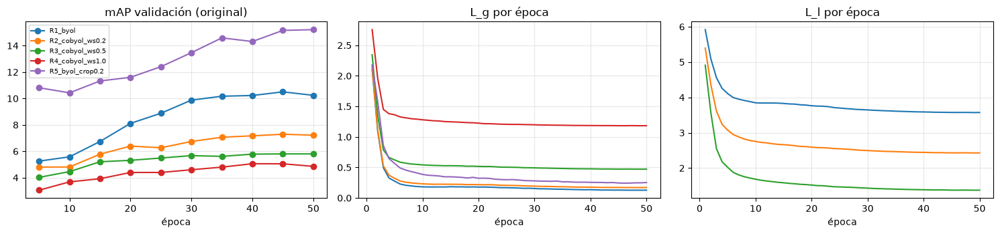

In [19]:
# Selección de w_s (solo con validación, mAP original)
cands = {n: s for n, s in SUMMARIES.items() if s['cfg']['w_s'] > 0 and s['cfg']['crop_min_scale'] == CFG['crop_min_scale']
         and s['cfg']['arch'] == CFG['arch'] and s['hist']['val']}
BEST_CO = max(cands, key=lambda n: SUMMARIES[n]['best_val_mAP'])
BEST_WS = SUMMARIES[BEST_CO]['cfg']['w_s']
print('Mejor CO-BYOL:', BEST_CO, '| w_s =', BEST_WS, '| mAP val =', round(SUMMARIES[BEST_CO]['best_val_mAP'], 2))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for n, s in SUMMARIES.items():
    v = s['hist']['val']
    axes[0].plot([r['epoch'] for r in v], [r['mAP_orig'] for r in v], marker='o', label=n)
    axes[1].plot(s['hist']['epoch'], s['hist']['L_g'], label=n)
    if s['cfg']['w_s'] > 0:
        axes[2].plot(s['hist']['epoch'], s['hist']['L_l'], label=n)
for ax, t in zip(axes, ['mAP validación (original)', 'L_g por época', 'L_l por época']):
    ax.set_title(t); ax.set_xlabel('época'); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7); plt.tight_layout(); finish(fig, '08_curvas_validacion')

### Ablación: ¿la pérdida local reemplaza al recorte agresivo?

El diseño es 2×2: {BYOL, CO-BYOL} × {recorte suave 0.8, recorte agresivo 0.2}. Según el paper, la ganancia de CO-BYOL debería ser mayor con el recorte suave.

- **Ablación alternativa** (si falta tiempo): número de pares locales `n_local` ∈ {1, 8, 32}, que replica la Tabla 3 del paper.

In [20]:
ABL = {'R6_cobyol_best_crop0.2': dict(w_s=BEST_WS, crop_min_scale=0.2)}
# Alternativa: ABL = {f'A_nlocal{k}': dict(w_s=BEST_WS, n_local=k) for k in [1, 8]}
if SMOKE_TEST:
    ABL = {}
for name, over in ABL.items():
    SUMMARIES[name] = train_run(name, {**CFG, **over}, TRAIN_U8, val)

SUMMARIES = load_summaries()
def vmap(n, k='mAP_orig'):
    return round(max(r[k] for r in SUMMARIES[n]['hist']['val']), 2) if n in SUMMARIES else None

abl = pd.DataFrame({
    'recorte': ['suave (0.8)', 'agresivo (0.2)'],
    'BYOL mAP': [vmap('R1_byol'), vmap('R5_byol_crop0.2')],
    'CO-BYOL mAP': [vmap(BEST_CO), vmap('R6_cobyol_best_crop0.2')],
    'BYOL mAP baja': [vmap('R1_byol', 'mAP_low'), vmap('R5_byol_crop0.2', 'mAP_low')],
    'CO-BYOL mAP baja': [vmap(BEST_CO, 'mAP_low'), vmap('R6_cobyol_best_crop0.2', 'mAP_low')],
})
abl['ganancia CO-BYOL'] = abl['CO-BYOL mAP'] - abl['BYOL mAP']
display(abl)

[R6_cobyol_best_crop0.2] 11043 imágenes, 345 iteraciones/época, arch=resnet50, w_s=0.2, recorte mín.=0.2


[R6_cobyol_best_crop0.2] época 1/50  L_g=2.2223  L_l=5.9457  85s


[R6_cobyol_best_crop0.2] época 2/50  L_g=1.6107  L_l=5.4533  85s


[R6_cobyol_best_crop0.2] época 3/50  L_g=0.8685  L_l=4.8791  86s


[R6_cobyol_best_crop0.2] época 4/50  L_g=0.6865  L_l=4.5685  85s


[R6_cobyol_best_crop0.2] época 5/50  L_g=0.6158  L_l=4.3835  86s  | val mAP=9.64  R1=20.00  mAP baja=8.02


[R6_cobyol_best_crop0.2] época 6/50  L_g=0.5483  L_l=4.2388  85s


[R6_cobyol_best_crop0.2] época 7/50  L_g=0.5086  L_l=4.1592  85s


[R6_cobyol_best_crop0.2] época 8/50  L_g=0.4796  L_l=4.1095  85s


[R6_cobyol_best_crop0.2] época 9/50  L_g=0.4582  L_l=4.0696  76s


[R6_cobyol_best_crop0.2] época 10/50  L_g=0.4305  L_l=4.0265  85s  | val mAP=8.78  R1=18.00  mAP baja=7.01


[R6_cobyol_best_crop0.2] época 11/50  L_g=0.4221  L_l=3.9896  86s


[R6_cobyol_best_crop0.2] época 12/50  L_g=0.4205  L_l=3.9905  85s


[R6_cobyol_best_crop0.2] época 13/50  L_g=0.4138  L_l=3.9861  86s


[R6_cobyol_best_crop0.2] época 14/50  L_g=0.3955  L_l=3.9675  85s


[R6_cobyol_best_crop0.2] época 15/50  L_g=0.3936  L_l=3.9499  86s  | val mAP=8.88  R1=15.00  mAP baja=7.97


[R6_cobyol_best_crop0.2] época 16/50  L_g=0.3877  L_l=3.9498  86s


[R6_cobyol_best_crop0.2] época 17/50  L_g=0.3828  L_l=3.9436  85s


[R6_cobyol_best_crop0.2] época 18/50  L_g=0.3693  L_l=3.9330  77s


[R6_cobyol_best_crop0.2] época 19/50  L_g=0.3800  L_l=3.9380  86s


[R6_cobyol_best_crop0.2] época 20/50  L_g=0.3608  L_l=3.9204  85s  | val mAP=10.88  R1=21.00  mAP baja=9.19


[R6_cobyol_best_crop0.2] época 21/50  L_g=0.3626  L_l=3.9234  85s


[R6_cobyol_best_crop0.2] época 22/50  L_g=0.3581  L_l=3.9161  86s


[R6_cobyol_best_crop0.2] época 23/50  L_g=0.3440  L_l=3.8985  85s


[R6_cobyol_best_crop0.2] época 24/50  L_g=0.3402  L_l=3.8955  86s


[R6_cobyol_best_crop0.2] época 25/50  L_g=0.3383  L_l=3.8931  85s  | val mAP=10.39  R1=21.00  mAP baja=7.59


[R6_cobyol_best_crop0.2] época 26/50  L_g=0.3410  L_l=3.8861  77s


[R6_cobyol_best_crop0.2] época 27/50  L_g=0.3352  L_l=3.8789  85s


[R6_cobyol_best_crop0.2] época 28/50  L_g=0.3245  L_l=3.8687  86s


[R6_cobyol_best_crop0.2] época 29/50  L_g=0.3216  L_l=3.8672  85s


[R6_cobyol_best_crop0.2] época 30/50  L_g=0.3186  L_l=3.8659  86s  | val mAP=10.43  R1=20.00  mAP baja=7.60


[R6_cobyol_best_crop0.2] época 31/50  L_g=0.3117  L_l=3.8618  85s


[R6_cobyol_best_crop0.2] época 32/50  L_g=0.3106  L_l=3.8605  85s


[R6_cobyol_best_crop0.2] época 33/50  L_g=0.3090  L_l=3.8546  85s


[R6_cobyol_best_crop0.2] época 34/50  L_g=0.3137  L_l=3.8603  86s


[R6_cobyol_best_crop0.2] época 35/50  L_g=0.3024  L_l=3.8449  70s  | val mAP=11.30  R1=21.00  mAP baja=7.08


[R6_cobyol_best_crop0.2] época 36/50  L_g=0.3001  L_l=3.8448  86s


[R6_cobyol_best_crop0.2] época 37/50  L_g=0.2953  L_l=3.8370  85s


[R6_cobyol_best_crop0.2] época 38/50  L_g=0.2955  L_l=3.8327  85s


[R6_cobyol_best_crop0.2] época 39/50  L_g=0.2928  L_l=3.8307  85s


[R6_cobyol_best_crop0.2] época 40/50  L_g=0.2907  L_l=3.8271  86s  | val mAP=10.90  R1=19.00  mAP baja=7.59


[R6_cobyol_best_crop0.2] época 41/50  L_g=0.2897  L_l=3.8245  85s


[R6_cobyol_best_crop0.2] época 42/50  L_g=0.2879  L_l=3.8227  86s


[R6_cobyol_best_crop0.2] época 43/50  L_g=0.2854  L_l=3.8171  85s


[R6_cobyol_best_crop0.2] época 44/50  L_g=0.2881  L_l=3.8211  77s


[R6_cobyol_best_crop0.2] época 45/50  L_g=0.2795  L_l=3.8073  84s  | val mAP=11.24  R1=19.00  mAP baja=7.43


[R6_cobyol_best_crop0.2] época 46/50  L_g=0.2803  L_l=3.8109  86s


[R6_cobyol_best_crop0.2] época 47/50  L_g=0.2790  L_l=3.8098  85s


[R6_cobyol_best_crop0.2] época 48/50  L_g=0.2830  L_l=3.8137  86s


[R6_cobyol_best_crop0.2] época 49/50  L_g=0.2838  L_l=3.8137  85s


[R6_cobyol_best_crop0.2] época 50/50  L_g=0.2882  L_l=3.8186  86s  | val mAP=11.16  R1=19.00  mAP baja=7.46


,recorte,BYOL mAP,CO-BYOL mAP,BYOL mAP baja,CO-BYOL mAP baja,ganancia CO-BYOL
0,suave (0.8),10.50,7.29,9.32,6.59,-3.21
1,agresivo (0.2),15.21,11.30,10.31,9.19,-3.91


### Ablación de arquitectura: ¿cuánto aporta RF99-ResNet50 y cuánto la pérdida local?

Tabla 2×2 análoga a la Tabla 6 del paper: {ResNet50 ImageNet, RF99-ResNet50 desde cero} × {BYOL, CO-BYOL}. Dentro de cada fila, la ganancia CO-BYOL − BYOL aísla el aporte de la pérdida local-global.

In [21]:
if any(n in SUMMARIES for n in RF_EXPERIMENTS):
    def pair(byol, co, k='mAP_orig'):
        return vmap(byol, k) if byol in SUMMARIES else None, vmap(co, k) if co in SUMMARIES else None
    rows = []
    for nombre, byol, co in [('ResNet50 ImageNet (R1 / mejor CO-BYOL)', 'R1_byol', BEST_CO),
                             ('RF99-ResNet50 desde cero (R9 / R10)', 'R9_byol_rf99', 'R10_cobyol_rf99')]:
        (b, c), (bl, cl) = pair(byol, co), pair(byol, co, 'mAP_low')
        rows.append({'arquitectura': nombre, 'BYOL mAP': b, 'CO-BYOL mAP': c,
                     'ganancia CO-BYOL': None if b is None or c is None else round(c - b, 2),
                     'BYOL mAP baja': bl, 'CO-BYOL mAP baja': cl,
                     'ganancia (baja)': None if bl is None or cl is None else round(cl - bl, 2)})
    display(pd.DataFrame(rows))
else:
    print('Sin corridas RF99 (LAB3_RF=0): se omite la ablación de arquitectura.')

Sin corridas RF99 (LAB3_RF=0): se omite la ablación de arquitectura.


## 9. Reentrenamiento final y evaluación en test

Los metadatos de `training.h5` indican: *"After choosing the configuration, combine these images with validation/query/images and validation/gallery/images, without using identity labels."*

1. **Reentrenamiento:** R7 (BYOL) y R8 (CO-BYOL con el mejor w_s) se entrenan desde cero con training + imágenes de validación (12 936, sin etiquetas). Cada uno usa el número de épocas de su mejor checkpoint de validación. Se reentrenan ambos para que la comparación siga siendo justa.
2. **Evaluación en test:** una sola vez, en ambas condiciones, con R0, R7 y R8. Para RF99 no se hizo reentrenamiento final (R11/R12, `LAB3_RF_FINAL=0`) por costo (~5–6 h por corrida); en su lugar, la rama `TEST_EXTRA` evalúa en test el **mejor checkpoint de validación** de R9 y R10, entrenados solo con `training.h5`. Esa rama estaba vacía en la ejecución original (R9/R10 aún no habían terminado) y se completó después con `eval_test_local.py`, que reutiliza `load_encoder` y `evaluate_both` de este notebook; ver 11.9.

In [22]:
FINAL_U8 = torch.from_numpy(np.concatenate([train['images'], val['query/images'], val['gallery/images']]))
if SMOKE_TEST:
    FINAL_U8 = FINAL_U8[:160]
print('Imágenes para el reentrenamiento final:', len(FINAL_U8))

FINAL = {'R7_final_byol': ('R1_byol', dict(w_s=0.0)),
         'R8_final_cobyol': (BEST_CO, dict(w_s=BEST_WS))}
RF_FINAL_ON = USE_RF and RF_FINAL and all(n in SUMMARIES for n in RF_EXPERIMENTS)
if RF_FINAL_ON:      # mismo protocolo que R7/R8: reentrenar con training + imágenes de validación, sin etiquetas
    FINAL['R11_final_byol_rf99'] = ('R9_byol_rf99', dict(RF_BASE, w_s=0.0))
    FINAL['R12_final_cobyol_rf99'] = ('R10_cobyol_rf99', dict(RF_BASE, w_s=RF_EXPERIMENTS['R10_cobyol_rf99']['w_s']))
# Sin reentrenamiento final RF: en test se usan los mejores checkpoints de validación (entrenados solo con training.h5)
TEST_EXTRA = {n: n for n in RF_EXPERIMENTS if USE_RF and not RF_FINAL_ON and n in SUMMARIES}
for name, (src, over) in FINAL.items():
    ep = SUMMARIES[src]['best_epoch'] or CFG['epochs']
    ep = max(ep, CFG['warmup_epochs'] + 1)
    print(f'{name}: {ep} épocas (mejor época de {src})')
    SUMMARIES[name] = train_run(name, {**CFG, **over, 'epochs': ep}, FINAL_U8, val_data=None)

Imágenes para el reentrenamiento final: 12936
R7_final_byol: 45 épocas (mejor época de R1_byol)


[R7_final_byol] 12936 imágenes, 404 iteraciones/época, arch=resnet50, w_s=0.0, recorte mín.=0.8


[R7_final_byol] época 1/45  L_g=2.0763  L_l=0.0000  94s


[R7_final_byol] época 2/45  L_g=0.9696  L_l=0.0000  84s


[R7_final_byol] época 3/45  L_g=0.4510  L_l=0.0000  92s


[R7_final_byol] época 4/45  L_g=0.3135  L_l=0.0000  90s


[R7_final_byol] época 5/45  L_g=0.2497  L_l=0.0000  91s


[R7_final_byol] época 6/45  L_g=0.2217  L_l=0.0000  92s


[R7_final_byol] época 7/45  L_g=0.2032  L_l=0.0000  94s


[R7_final_byol] época 8/45  L_g=0.1919  L_l=0.0000  93s


[R7_final_byol] época 9/45  L_g=0.1866  L_l=0.0000  94s


[R7_final_byol] época 10/45  L_g=0.1838  L_l=0.0000  88s


[R7_final_byol] época 11/45  L_g=0.1858  L_l=0.0000  92s


[R7_final_byol] época 12/45  L_g=0.1836  L_l=0.0000  115s


[R7_final_byol] época 13/45  L_g=0.1870  L_l=0.0000  198s


[R7_final_byol] época 14/45  L_g=0.1838  L_l=0.0000  199s


[R7_final_byol] época 15/45  L_g=0.1867  L_l=0.0000  190s


[R7_final_byol] época 16/45  L_g=0.1865  L_l=0.0000  193s


[R7_final_byol] época 17/45  L_g=0.1884  L_l=0.0000  101s


[R7_final_byol] época 18/45  L_g=0.1849  L_l=0.0000  84s


[R7_final_byol] época 19/45  L_g=0.1834  L_l=0.0000  92s


[R7_final_byol] época 20/45  L_g=0.1811  L_l=0.0000  89s


[R7_final_byol] época 21/45  L_g=0.1784  L_l=0.0000  90s


[R7_final_byol] época 22/45  L_g=0.1747  L_l=0.0000  90s


[R7_final_byol] época 23/45  L_g=0.1698  L_l=0.0000  91s


[R7_final_byol] época 24/45  L_g=0.1700  L_l=0.0000  90s


[R7_final_byol] época 25/45  L_g=0.1669  L_l=0.0000  93s


[R7_final_byol] época 26/45  L_g=0.1642  L_l=0.0000  85s


[R7_final_byol] época 27/45  L_g=0.1612  L_l=0.0000  90s


[R7_final_byol] época 28/45  L_g=0.1580  L_l=0.0000  93s


[R7_final_byol] época 29/45  L_g=0.1547  L_l=0.0000  93s


[R7_final_byol] época 30/45  L_g=0.1518  L_l=0.0000  95s


[R7_final_byol] época 31/45  L_g=0.1509  L_l=0.0000  93s


[R7_final_byol] época 32/45  L_g=0.1467  L_l=0.0000  95s


[R7_final_byol] época 33/45  L_g=0.1435  L_l=0.0000  91s


[R7_final_byol] época 34/45  L_g=0.1422  L_l=0.0000  84s


[R7_final_byol] época 35/45  L_g=0.1387  L_l=0.0000  90s


[R7_final_byol] época 36/45  L_g=0.1376  L_l=0.0000  94s


[R7_final_byol] época 37/45  L_g=0.1379  L_l=0.0000  92s


[R7_final_byol] época 38/45  L_g=0.1352  L_l=0.0000  94s


[R7_final_byol] época 39/45  L_g=0.1354  L_l=0.0000  95s


[R7_final_byol] época 40/45  L_g=0.1333  L_l=0.0000  92s


[R7_final_byol] época 41/45  L_g=0.1332  L_l=0.0000  93s


[R7_final_byol] época 42/45  L_g=0.1315  L_l=0.0000  79s


[R7_final_byol] época 43/45  L_g=0.1319  L_l=0.0000  32s


[R7_final_byol] época 44/45  L_g=0.1317  L_l=0.0000  32s


[R7_final_byol] época 45/45  L_g=0.1305  L_l=0.0000  32s


R8_final_cobyol: 45 épocas (mejor época de R2_cobyol_ws0.2)


[R8_final_cobyol] 12936 imágenes, 404 iteraciones/época, arch=resnet50, w_s=0.2, recorte mín.=0.8


[R8_final_cobyol] época 1/45  L_g=2.1203  L_l=5.8929  35s


[R8_final_cobyol] época 2/45  L_g=0.9931  L_l=4.9989  35s


[R8_final_cobyol] época 3/45  L_g=0.4813  L_l=4.4964  35s


[R8_final_cobyol] época 4/45  L_g=0.3586  L_l=4.2062  35s


[R8_final_cobyol] época 5/45  L_g=0.3012  L_l=4.0515  35s


[R8_final_cobyol] época 6/45  L_g=0.2761  L_l=3.9659  35s


[R8_final_cobyol] época 7/45  L_g=0.2572  L_l=3.9017  35s


[R8_final_cobyol] época 8/45  L_g=0.2455  L_l=3.8723  35s


[R8_final_cobyol] época 9/45  L_g=0.2373  L_l=3.8451  35s


[R8_final_cobyol] época 10/45  L_g=0.2324  L_l=3.8174  37s


[R8_final_cobyol] época 11/45  L_g=0.2331  L_l=3.8151  37s


[R8_final_cobyol] época 12/45  L_g=0.2274  L_l=3.8035  36s


[R8_final_cobyol] época 13/45  L_g=0.2280  L_l=3.7969  35s


[R8_final_cobyol] época 14/45  L_g=0.2233  L_l=3.7842  35s


[R8_final_cobyol] época 15/45  L_g=0.2248  L_l=3.7924  35s


[R8_final_cobyol] época 16/45  L_g=0.2231  L_l=3.7879  37s


[R8_final_cobyol] época 17/45  L_g=0.2254  L_l=3.7814  37s


[R8_final_cobyol] época 18/45  L_g=0.2222  L_l=3.7787  37s


[R8_final_cobyol] época 19/45  L_g=0.2210  L_l=3.7694  37s


[R8_final_cobyol] época 20/45  L_g=0.2181  L_l=3.7531  38s


[R8_final_cobyol] época 21/45  L_g=0.2139  L_l=3.7400  37s


[R8_final_cobyol] época 22/45  L_g=0.2095  L_l=3.7262  38s


[R8_final_cobyol] época 23/45  L_g=0.2068  L_l=3.7208  38s


[R8_final_cobyol] época 24/45  L_g=0.2058  L_l=3.7145  37s


[R8_final_cobyol] época 25/45  L_g=0.2040  L_l=3.7122  36s


[R8_final_cobyol] época 26/45  L_g=0.2017  L_l=3.7045  35s


[R8_final_cobyol] época 27/45  L_g=0.1976  L_l=3.6941  35s


[R8_final_cobyol] época 28/45  L_g=0.1949  L_l=3.6846  35s


[R8_final_cobyol] época 29/45  L_g=0.1933  L_l=3.6795  37s


[R8_final_cobyol] época 30/45  L_g=0.1892  L_l=3.6699  37s


[R8_final_cobyol] época 31/45  L_g=0.1893  L_l=3.6690  37s


[R8_final_cobyol] época 32/45  L_g=0.1858  L_l=3.6627  35s


[R8_final_cobyol] época 33/45  L_g=0.1829  L_l=3.6579  37s


[R8_final_cobyol] época 34/45  L_g=0.1811  L_l=3.6526  37s


[R8_final_cobyol] época 35/45  L_g=0.1773  L_l=3.6458  36s


[R8_final_cobyol] época 36/45  L_g=0.1775  L_l=3.6441  35s


[R8_final_cobyol] época 37/45  L_g=0.1768  L_l=3.6436  35s


[R8_final_cobyol] época 38/45  L_g=0.1748  L_l=3.6389  35s


[R8_final_cobyol] época 39/45  L_g=0.1740  L_l=3.6376  36s


[R8_final_cobyol] época 40/45  L_g=0.1723  L_l=3.6338  36s


[R8_final_cobyol] época 41/45  L_g=0.1728  L_l=3.6338  35s


[R8_final_cobyol] época 42/45  L_g=0.1714  L_l=3.6313  35s


[R8_final_cobyol] época 43/45  L_g=0.1717  L_l=3.6319  35s


[R8_final_cobyol] época 44/45  L_g=0.1723  L_l=3.6337  35s


[R8_final_cobyol] época 45/45  L_g=0.1708  L_l=3.6307  35s


In [23]:
test_path = DATA_DIR / ('validation.h5' if SMOKE_TEST else 'testing.h5')   # en SMOKE_TEST no se usa test
test, _ = load_h5(test_path)
split_stats(test, 'Test')

TEST = {'R0_imagenet': evaluate_both(build_backbone(CFG['arch'], CFG['pretrained'], CFG['last_stride'])[0].to(DEVICE),
                                     test, CFG, return_details=True)}
for name in FINAL:
    TEST[name] = evaluate_both(load_encoder(name, CFG, 'last'), test, CFG, return_details=True)
for name in TEST_EXTRA:
    TEST[name] = evaluate_both(load_encoder(name, CFG, 'best'), test, CFG, return_details=True)

test_table = pd.DataFrame([{'modelo': n, **{k: round(v, 2) for k, v in flat_metrics(r).items()}} for n, r in TEST.items()])
(OUT_DIR / 'test_results.json').write_text(test_table.to_json(orient='records', indent=1))
display(test_table)

Test: 3368 queries, 19732 gallery | identidades query 750 | gallery id=-1: 3819, id=0: 2798 | positivos válidos por query: min 1, media 14.7
[R9_byol_rf99 / R10_cobyol_rf99] evaluados con best_encoder.pt en una ejecución posterior (eval_test_local.py, RTX 4060); filas añadidas a runs/test_results.json


,modelo,mAP_orig,R1_orig,R5_orig,R10_orig,mAP_low,R1_low,R5_low,R10_low,delta_mAP
0,R0_imagenet,3.13,9.89,20.37,26.37,1.54,3.24,8.43,12.56,1.59
1,R7_final_byol,2.85,8.64,18.02,24.08,2.64,7.51,17.43,23.28,0.21
2,R8_final_cobyol,2.12,6.18,13.03,16.83,2.00,5.55,11.79,16.48,0.12
3,R9_byol_rf99,1.29,3.27,9.41,13.57,1.10,2.02,7.10,10.45,0.19
4,R10_cobyol_rf99,2.34,7.33,16.51,22.15,2.18,5.64,14.79,20.58,0.16


## 10. Análisis de resultados

### 10.1 Aciertos y fallos

- **Aciertos:** queries de CO-BYOL con Rank-1 correcto y AP alto.
- **Fallos:** queries con Rank-1 incorrecto y el AP más bajo. Para los mismos fallos se muestra también lo que recupera BYOL.

En las figuras, el borde verde indica la misma persona y el rojo una persona distinta. Se anota la cámara de cada imagen.

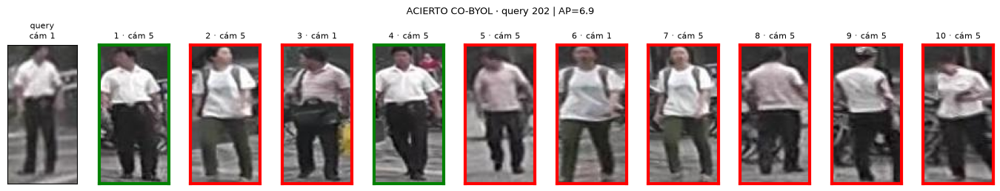

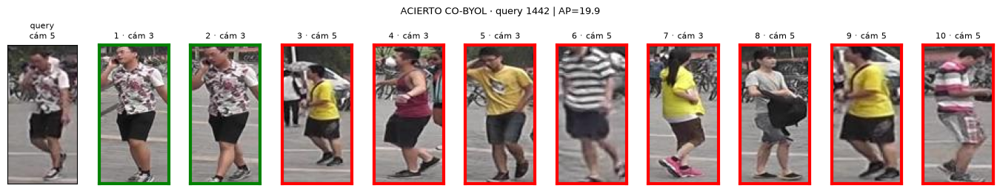

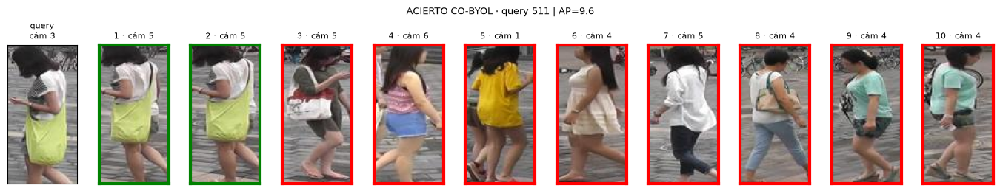

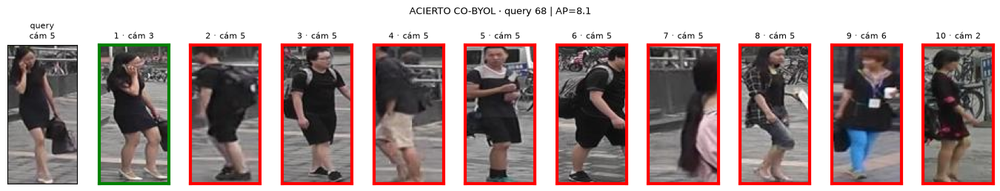

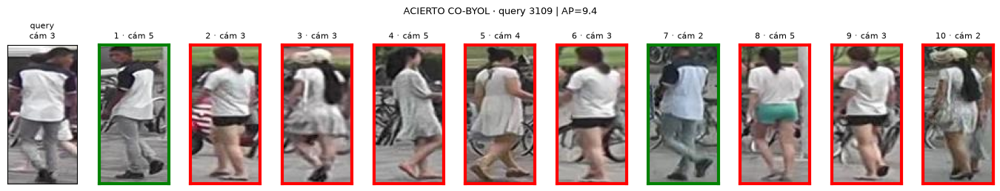

...

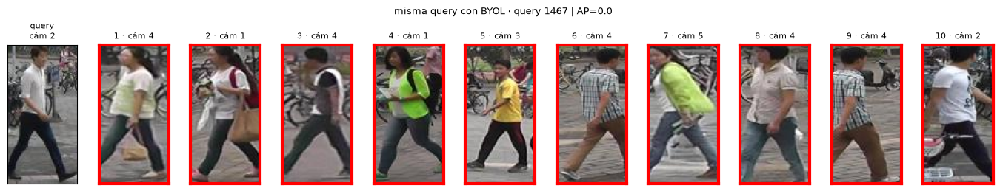

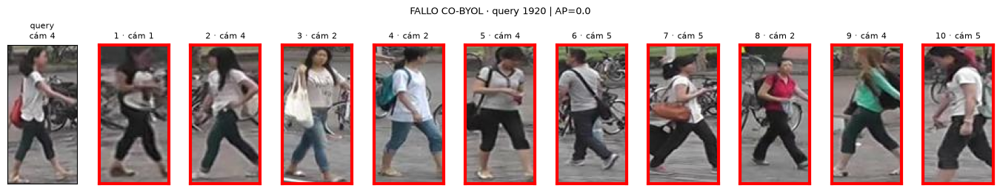

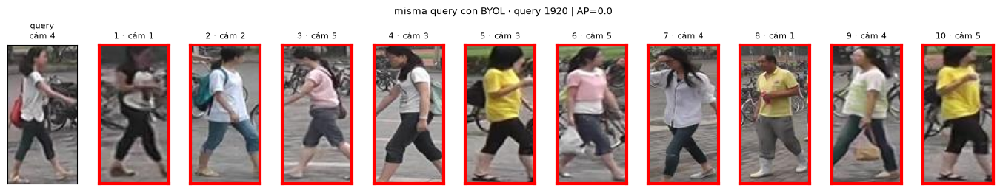

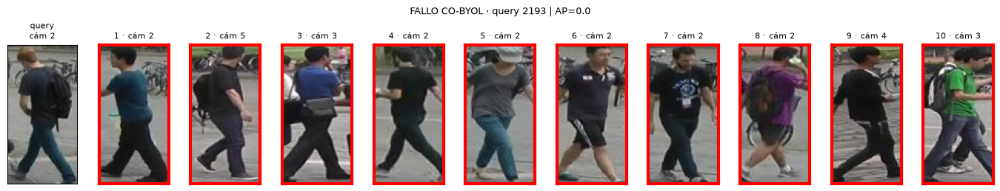

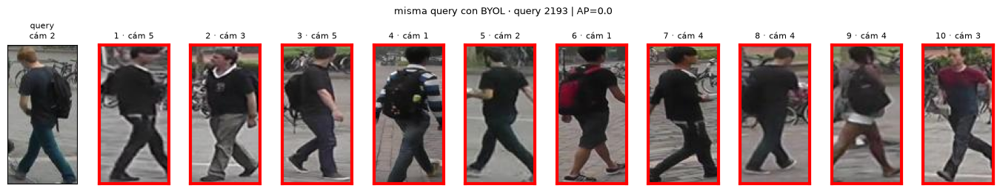

In [24]:
def show_ranking(qi, r, cond, data, title, fname, k=10):
    q_img = data['query/images_low_resolution' if cond == 'low' else 'query/images'][qi]
    tops = r[cond + '_tops'][qi][:k]
    qp, qc = data['query/person_ids'][qi], data['query/camera_ids'][qi]
    fig, axes = plt.subplots(1, k + 1, figsize=(1.25 * (k + 1), 2.6))
    axes[0].imshow(np.transpose(q_img, (1, 2, 0))); axes[0].set_title(f'query\ncám {qc}', fontsize=8)
    for j, gi in enumerate(tops):
        ax = axes[j + 1]
        ok = data['gallery/person_ids'][gi] == qp
        ax.imshow(np.transpose(data['gallery/images'][gi], (1, 2, 0)))
        for sp in ax.spines.values():
            sp.set_edgecolor('green' if ok else 'red'); sp.set_linewidth(3)
        ax.set_title(f'{j + 1} · cám {data["gallery/camera_ids"][gi]}', fontsize=8)
    for ax in axes:
        ax.set_xticks([]); ax.set_yticks([])
    fig.suptitle(f'{title} | AP={100 * r[cond + "_aps"][qi]:.1f}', fontsize=9)
    plt.tight_layout(); finish(fig, fname)

CO, BY = TEST['R8_final_cobyol'], TEST['R7_final_byol']
aps = CO['orig_aps']
r1_ok = np.array([t[0] >= 0 and test['gallery/person_ids'][t[0]] == p for t, p in zip(CO['orig_tops'], test['query/person_ids'])])
rng = np.random.RandomState(0)
good = np.flatnonzero(r1_ok & (aps > np.nanpercentile(aps, 80)))
SUCCESSES = rng.choice(good, min(5, len(good)), replace=False)
FAILURES = np.flatnonzero(~r1_ok & ~np.isnan(aps))
FAILURES = FAILURES[np.argsort(aps[FAILURES])][:5]

for qi in SUCCESSES:
    show_ranking(qi, CO, 'orig', test, f'ACIERTO CO-BYOL · query {qi}', f'10_acierto_q{qi}')
for qi in FAILURES:
    show_ranking(qi, CO, 'orig', test, f'FALLO CO-BYOL · query {qi}', f'10_fallo_q{qi}_cobyol')
    show_ranking(qi, BY, 'orig', test, f'  misma query con BYOL · query {qi}', f'10_fallo_q{qi}_byol')

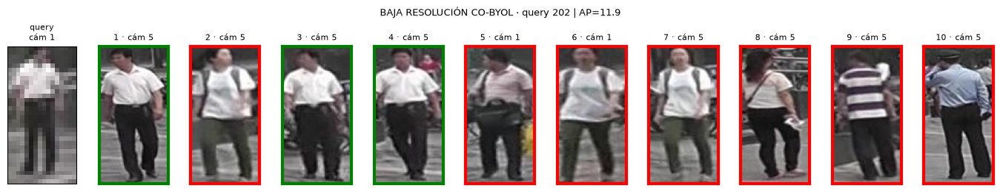

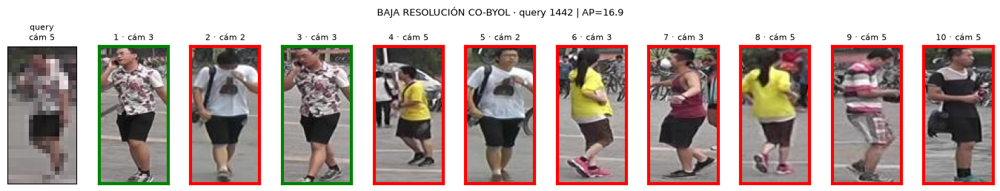

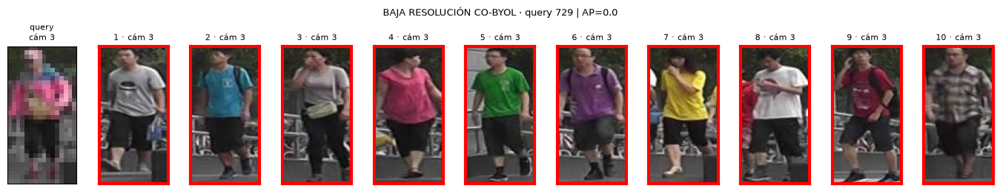

R0_imagenet       : 3035 errores en Rank-1, 66.9% de ellos son de la misma cámara que la query
R7_final_byol     : 3077 errores en Rank-1, 70.4% de ellos son de la misma cámara que la query
R8_final_cobyol   : 3160 errores en Rank-1, 79.4% de ellos son de la misma cámara que la query


In [25]:
# Mismas queries con baja resolución: ¿qué se pierde?
for qi in list(SUCCESSES[:2]) + list(FAILURES[:1]):
    show_ranking(qi, CO, 'low', test, f'BAJA RESOLUCIÓN CO-BYOL · query {qi}', f'10_baja_res_q{qi}')

# Indicador de sesgo de cámara: cuando el Rank-1 falla, ¿la imagen recuperada es de la misma cámara que la query?
def same_cam_errors(r):
    t1 = r['orig_tops'][:, 0]
    wrong = (test['gallery/person_ids'][t1] != test['query/person_ids']) & ~np.isnan(r['orig_aps'])
    same = test['gallery/camera_ids'][t1] == test['query/camera_ids']
    return 100 * (wrong & same).sum() / max(1, wrong.sum()), int(wrong.sum())

for n in TEST:
    pct, nw = same_cam_errors(TEST[n])
    print(f'{n:18s}: {nw} errores en Rank-1, {pct:.1f}% de ellos son de la misma cámara que la query')

**Explicación de los 5 aciertos y 5 fallos** (completar después de ver las figuras):

| Caso | Query | Categoría | Explicación |
|---|---|---|---|
| Acierto 1 | | | |
| Acierto 2 | | | |
| Acierto 3 | | | |
| Acierto 4 | | | |
| Acierto 5 | | | |
| Fallo 1 | | ropa similar / punto de vista / oclusión / fondo o cámara / baja resolución / anotación | |
| Fallo 2 | | | |
| Fallo 3 | | | |
| Fallo 4 | | | |
| Fallo 5 | | | |

### 10.2 Mecanismo de CO-SSL: similitud entre parches (análogo a la Fig. 5 del paper)

Si CO-SSL funciona como dice el paper, los parches locales de una misma imagen deben parecerse más entre sí y a la representación global.

In [26]:
@torch.no_grad()
def patch_stats(encoder, imgs_u8, n=512):
    x = prep_eval(torch.as_tensor(imgs_u8[:n]).to(DEVICE), CFG['img_h'], CFG['img_w'])
    L = F.normalize(encoder.eval()(x).float().flatten(2), dim=1)        # (n, D, P)
    h = F.normalize(encoder(x).float().mean(dim=(2, 3)), dim=1)          # (n, D)
    S = torch.einsum('bdp,bdq->bpq', L, L)
    P = S.shape[-1]
    intra = (S.sum((1, 2)) - P) / (P * (P - 1))                           # media fuera de la diagonal
    to_glob = torch.einsum('bdp,bd->bp', L, h)
    return intra.mean().item(), to_glob.mean().item(), to_glob

idx = np.random.RandomState(1).permutation(len(test['gallery/images']))[:512]
G_SUB = test['gallery/images'][np.sort(idx)]
ENCS = {'R0_imagenet': build_backbone(CFG['arch'], CFG['pretrained'], CFG['last_stride'])[0].to(DEVICE),
        'R7_final_byol': load_encoder('R7_final_byol', CFG, 'last'),
        'R8_final_cobyol': load_encoder('R8_final_cobyol', CFG, 'last')}
for n in [n for n in FINAL if 'rf99' in n] + list(TEST_EXTRA):
    ENCS[n] = load_encoder(n, CFG, 'last' if n in FINAL else 'best')
rows, MAPS = [], {}
for n, enc in ENCS.items():
    intra, glob, MAPS[n] = patch_stats(enc, G_SUB)
    rows.append({'modelo': n, 'cos parche-parche (intra-imagen)': round(intra, 3), 'cos parche-global': round(glob, 3)})
display(pd.DataFrame(rows))

,modelo,cos parche-parche (intra-imagen),cos parche-global
0,R0_imagenet,0.539,0.740
1,R7_final_byol,0.420,0.659
2,R8_final_cobyol,0.505,0.718


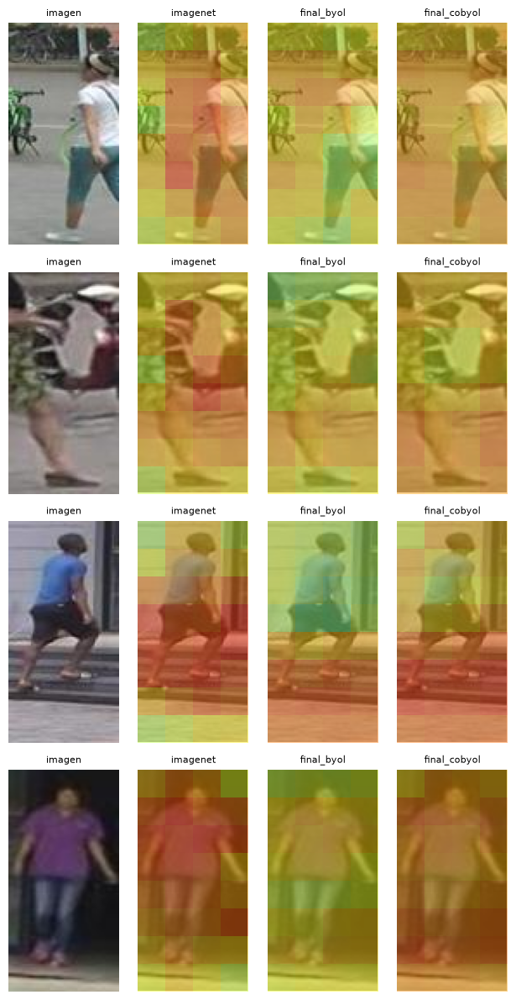

In [27]:
# Mapas cos(parche_i, global) sobre la persona: ¿qué partes "ven el todo"? ¿también el fondo?
def grid_hw(P):      # (alto, ancho) del mapa local: la imagen es 2:1, así que alto = 2 * ancho (8x4, 16x8, ...)
    w_ = int(round((P / 2) ** 0.5)); return P // w_, w_
sel = [0, 1, 2, 3]
fig, axes = plt.subplots(len(sel), 1 + len(ENCS), figsize=(1.6 * (1 + len(ENCS)), 3 * len(sel)))
for i, k in enumerate(sel):
    axes[i, 0].imshow(np.transpose(G_SUB[k], (1, 2, 0))); axes[i, 0].set_title('imagen', fontsize=8)
    for j, n in enumerate(ENCS):
        mp = MAPS[n][k].view(*grid_hw(MAPS[n].shape[1])).cpu().numpy()
        axes[i, j + 1].imshow(np.transpose(G_SUB[k], (1, 2, 0)))
        axes[i, j + 1].imshow(mp, cmap='jet', alpha=0.45, extent=(0, 64, 128, 0), vmin=0, vmax=1)
        axes[i, j + 1].set_title(n.split('_', 1)[1], fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
plt.tight_layout(); finish(fig, '10_mapas_parche_global')

### 10.3 Coste computacional

In [28]:
display(pd.DataFrame([{'run': n, 'arch': s['cfg']['arch'], 'w_s': s['cfg']['w_s'], 'épocas': len(s['hist']['epoch']),
               's/época': round(s['sec_per_epoch'], 1)} for n, s in load_summaries().items()]))

,run,arch,w_s,épocas,s/época
0,R1_byol,resnet50,0.0,50,85.2
1,R2_cobyol_ws0.2,resnet50,0.2,50,93.0
2,R3_cobyol_ws0.5,resnet50,0.5,50,84.3
3,R4_cobyol_ws1.0,resnet50,1.0,50,86.9
4,R5_byol_crop0.2,resnet50,0.0,50,78.7
5,R6_cobyol_best_crop0.2,resnet50,0.2,50,84.2
6,R7_final_byol,resnet50,0.0,45,97.0
7,R8_final_cobyol,resnet50,0.2,45,35.8


### 10.4 Limitaciones y diferencias respecto al paper

**Diferencias de implementación:**

| Aspecto | Paper | Nuestra implementación | Motivo |
|---|---|---|---|
| Backbone | RF99-ResNet50 desde cero | ResNet50 preentrenada en ImageNet (R1–R8) **y** RF99-ResNet50 desde cero, implementada por el grupo (R9–R12) | Con solo 12 936 imágenes la línea principal usa pesos de ImageNet; RF-ResNet no admite pesos preentrenados, por eso se entrena aparte |
| Campo receptivo local | ~99 px (20% de la imagen) | Teórico ~425 px en layer4 (R1–R8; mayor que la imagen de 256×128) y 99 px en RF99 (R9–R12) | Simplificación declarada; el campo receptivo efectivo es más local (Fig. 2 del paper) |
| Entrada / n² | 224×224 / 196 (RF99) | 256×128 / 32 (ResNet50) y 128 (RF99, mapa 16×8) | Proporción de persona |
| Augmentaciones | C/R escala mínima 0.2 o 0.9 + color | Recorte suave 0.8, baja resolución simulada, random erasing | Re-ID requiere alineación del cuerpo; consultas de 32×16 |
| Optimizador | LARS, 100–1000 épocas | AdamW, ~50 épocas (R1–R8) y 60 (R9–R10, desde cero) | Datos y tiempo de cómputo (límite de 8 h por job en KHIPU) |
| Evaluación | Linear probe en ImageNet | Recuperación: mAP y CMC | Lo exige el laboratorio |

**Limitaciones:**

- Sin pseudo-etiquetas, nada acerca dos fotos de la misma persona tomadas por cámaras distintas. Por eso el techo queda lejos de los métodos con clustering.
- La pérdida local alinea también los parches de fondo, lo que puede reforzar el sesgo de cámara (ver el indicador de la sección 10.1).
- La validación es pequeña (100 queries) y se usó una sola semilla.
- El paper no evalúa Re-ID ni baja resolución, así que nuestros resultados son una extrapolación.
- R9–R10 usan 60 épocas desde cero y `w_s = 0.5` fijo (Tabla 7 del paper): no se barrió `w_s` con RF99 por costo. R9 se lanzó configurada a 100 épocas y el límite de 8 h la detuvo en la 60 (`status: interrupted` en su `done.json`), por lo que su tasa de aprendizaje (coseno) no llegó a decaer como en R10; R10 completó su schedule de 60 épocas. El embedding de Re-ID es el avgpool del encoder (variante *RF99-b* de la Tabla 6), no la salida del MLP.
- Comparar R9/R10 con R1–R8 mezcla arquitectura y presupuesto de épocas; la comparación limpia del aporte de CO-SSL es R9 vs R10.
- R9 y R10 se evalúan en test con el mejor checkpoint de validación y entrenados solo con `training.h5` (sin el reentrenamiento final con training + validación que sí tienen R7/R8), así que su comparación con R7/R8 es ligeramente desfavorable para RF99.

## 11. Comparación global de todos los experimentos (R0–R10)

Esta sección **no entrena ni evalúa nada**: solo lee los `done.json` de cada corrida (`runs/R*/done.json`) y `runs/test_results.json`, por lo que puede ejecutarse sola (sin GPU ni dataset) para regenerar las figuras.

| Bloque | Pregunta | Referencia en el paper (Aubret et al., 2026) |
|---|---|---|
| 11.1 | Resumen numérico de todas las corridas | — |
| 11.2 | ¿Qué corrida recupera mejor en validación (original y baja resolución)? | — |
| 11.3 | ¿Cómo evoluciona el mAP y las pérdidas por época? | Fig. 3 / Tabla 1 (CO-SSL aprende más rápido) |
| 11.4 | Sensibilidad a `w_s` | Tabla 7 (óptimo en 0.2–0.5) |
| 11.5 | ¿La pérdida local reemplaza al recorte agresivo? | Fig. 4 (CO-BYOL compensa C/R suave) |
| 11.6 | Arquitectura × pérdida: ResNet50 vs RF99-ResNet50 | Tabla 6 (la ganancia es mayor con RF99) |
| 11.7 | Robustez a baja resolución y curvas CMC | Tablas 4–5 (robustez) |
| 11.8 | Coste computacional | Tabla 2 (sobrecoste de CO-SSL / RF99) |
| 11.9 | Resultados en test | — |

**Nota sobre R10:** el `done.json` de `R10_cobyol_rf99` corresponde a la corrida completa de 60 épocas (mejor época 45, mAP val = 7.76). El intento en KHIPU (job 59053) terminó por *CUDA out of memory* en la época 9 y no generó resumen.

**Nota sobre la evaluación en test de R9 y R10:** se realizó en una ejecución posterior con `eval_test_local.py` (mismas funciones `load_encoder`/`evaluate_both`/`flat_metrics`, checkpoint `best_encoder.pt`, GPU RTX 4060, ~2 min por modelo); las filas se añadieron a `runs/test_results.json` y el detalle por checkpoint (`best` y `last`) está en `runs/R9_byol_rf99/test_metrics.json` y `runs/R10_cobyol_rf99/test_metrics.json`.

**Réplica de R10 en KHIPU (job 58967, RTX A6000, misma configuración):** mejor época 50, mAP val = 8.07 (baja: 7.46), frente a 7.76 de la corrida local usada en las tablas; su `done.json` está en `runs/R10_cobyol_rf99_khipu/`. La diferencia (0.3 de mAP) da una idea de la variabilidad entre ejecuciones con la misma semilla en hardware distinto.

In [ ]:
# 11.0 Carga de resúmenes (sin entrenamiento)
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RUNS = OUT_DIR if 'OUT_DIR' in globals() else Path('runs')
FIGS = RUNS / 'figs'; FIGS.mkdir(parents=True, exist_ok=True)

ALL = {}
for d in sorted(RUNS.glob('R*'), key=lambda p: int(p.name.split('_')[0][1:])):
    if (d / 'done.json').exists():
        ALL[d.name] = json.loads((d / 'done.json').read_text())

# R0 (ResNet50 ImageNet sin SSL) en validación: se toma de la sección 8 si existe; si no, del log del job 58817.
R0_VAL = ({k: float(v) for k, v in flat_metrics(R0).items()} if 'R0' in globals() and 'flat_metrics' in globals() else
          dict(mAP_orig=10.41, R1_orig=20.0, R5_orig=38.0, R10_orig=46.0,
               mAP_low=5.29, R1_low=7.0, R5_low=18.0, R10_low=29.0, delta_mAP=5.12))

# Color por familia (fijo por entidad, no por ranking)
GRAY = '#8a8984'
COLOR = {
    'R0_imagenet':            GRAY,
    'R1_byol':                '#2a78d6',
    'R2_cobyol_ws0.2':        '#eb6834',
    'R3_cobyol_ws0.5':        '#1baf7a',
    'R4_cobyol_ws1.0':        '#eda100',
    'R5_byol_crop0.2':        '#e87ba4',
    'R6_cobyol_best_crop0.2': '#008300',
    'R7_final_byol':          '#2a78d6',
    'R8_final_cobyol':        '#eb6834',
    'R9_byol_rf99':           '#6250d6',
    'R10_cobyol_rf99':        '#e34948',
}
SHORT = {n: n.split('_', 1)[0] + ' ' + n.split('_', 1)[1].replace('_', ' ') for n in COLOR}

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.titleweight': 'bold', 'font.size': 9.5})

def save(fig, name):
    fig.savefig(FIGS / f'{name}.png', dpi=130, bbox_inches='tight'); plt.show()

def best_val(s):
    return max(s['hist']['val'], key=lambda r: r['mAP_orig']) if s['hist']['val'] else None

print('Corridas encontradas:', list(ALL))

Corridas encontradas: ['R1_byol', 'R2_cobyol_ws0.2', 'R3_cobyol_ws0.5', 'R4_cobyol_ws1.0', 'R5_byol_crop0.2', 'R6_cobyol_best_crop0.2', 'R7_final_byol', 'R8_final_cobyol', 'R9_byol_rf99', 'R10_cobyol_rf99']


### 11.1 Tabla resumen de todas las corridas (mejor checkpoint de validación)

In [ ]:
rows = [{'run': 'R0_imagenet', 'arquitectura': 'ResNet50 (ImageNet)', 'método': 'sin SSL', 'w_s': None,
         'recorte_min': None, 'épocas': 0, 'batch': None, 'mejor_época': None,
         **{k: round(v, 2) for k, v in R0_VAL.items()}, 's/época': None, 'horas_GPU': 0.0}]
for n, s in ALL.items():
    c, b = s['cfg'], best_val(s)
    ep = len(s['hist']['epoch'])
    row = {'run': n,
           'arquitectura': 'RF99-ResNet50 (desde cero)' if c['arch'] == 'rf99' else 'ResNet50 (ImageNet)',
           'método': 'BYOL' if c['w_s'] == 0 else 'CO-BYOL',
           'w_s': c['w_s'], 'recorte_min': c['crop_min_scale'], 'épocas': ep, 'batch': c['batch_size'],
           'mejor_época': b['epoch'] if b else None}
    for k in ['mAP_orig', 'R1_orig', 'R5_orig', 'R10_orig', 'mAP_low', 'R1_low', 'R5_low', 'R10_low']:
        row[k] = round(b[k], 2) if b and k in b else None
    row['delta_mAP'] = round(b['mAP_orig'] - b['mAP_low'], 2) if b else None
    row['s/época'] = round(s['sec_per_epoch'], 1)
    row['horas_GPU'] = round(s['sec_per_epoch'] * ep / 3600, 2)
    rows.append(row)
SUMMARY = pd.DataFrame(rows).set_index('run')
display(SUMMARY)
print('R7 y R8 son reentrenamientos finales sin validación (se evalúan solo en test, sección 11.9).')
print('R9: corrida interrumpida a las 60/100 épocas (batch 64, schedule de LR para 100 épocas); R10: 60 épocas completas (batch 64).')

,arquitectura,método,w_s,recorte_min,épocas,batch,mejor_época,mAP_orig,R1_orig,R5_orig,R10_orig,mAP_low,R1_low,R5_low,R10_low,delta_mAP,s/época,horas_GPU
run,,,,,,,,,,,,,,,,,,
R0_imagenet,ResNet50 (ImageNet),sin SSL,NaN,NaN,0,NaN,NaN,10.41,20.0,38.0,46.0,5.29,7.0,18.0,29.0,5.12,NaN,0.00
R1_byol,ResNet50 (ImageNet),BYOL,0.0,0.8,50,32.0,45.0,10.50,22.0,39.0,48.0,9.32,17.0,35.0,44.0,1.18,85.2,1.18
R2_cobyol_ws0.2,ResNet50 (ImageNet),CO-BYOL,0.2,0.8,50,32.0,45.0,7.29,12.0,26.0,29.0,6.56,11.0,25.0,28.0,0.73,93.0,1.29
R3_cobyol_ws0.5,ResNet50 (ImageNet),CO-BYOL,0.5,0.8,50,32.0,45.0,5.80,12.0,20.0,27.0,5.31,9.0,23.0,24.0,0.49,84.3,1.17
R4_cobyol_ws1.0,ResNet50 (ImageNet),CO-BYOL,1.0,0.8,50,32.0,40.0,5.06,11.0,19.0,24.0,4.53,9.0,19.0,24.0,0.53,86.9,1.21
R5_byol_crop0.2,ResNet50 (ImageNet),BYOL,0.0,0.2,50,32.0,50.0,15.21,28.0,45.0,50.0,9.80,21.0,33.0,38.0,5.41,78.7,1.09
R6_cobyol_best_crop0.2,ResNet50 (ImageNet),CO-BYOL,0.2,0.2,50,32.0,35.0,11.30,21.0,32.0,37.0,7.08,13.0,26.0,28.0,4.21,84.2,1.17
R7_final_byol,ResNet50 (ImageNet),BYOL,0.0,0.8,45,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,97.0,1.21
R8_final_cobyol,ResNet50 (ImageNet),CO-BYOL,0.2,0.8,45,32.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.8,0.45


R7 y R8 son reentrenamientos finales sin validación (se evalúan solo en test, sección 11.9).
R9: corrida interrumpida a las 60/100 épocas (batch 64, schedule de LR para 100 épocas); R10: 60 épocas completas (batch 64).


### 11.2 Mejor mAP de validación por corrida

Barras = mejor checkpoint de validación (100 queries). La línea punteada es R0 (ResNet50 ImageNet sin SSL). Con 100 queries, diferencias menores a ~2 puntos pueden ser ruido.

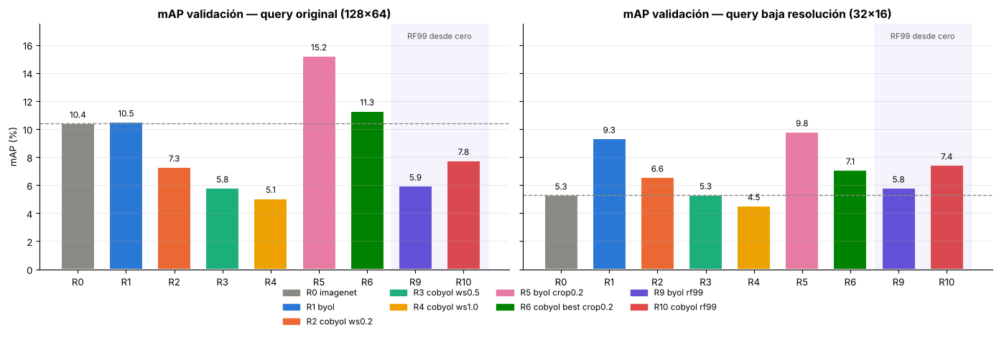

In [ ]:
val_runs = [n for n in ALL if best_val(ALL[n])]
names = ['R0_imagenet'] + val_runs
orig = [R0_VAL['mAP_orig']] + [best_val(ALL[n])['mAP_orig'] for n in val_runs]
low = [R0_VAL['mAP_low']] + [best_val(ALL[n])['mAP_low'] for n in val_runs]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), sharey=True)
for ax, vals, title in [(axes[0], orig, 'mAP validación — query original (128×64)'),
                        (axes[1], low, 'mAP validación — query baja resolución (32×16)')]:
    x = np.arange(len(names))
    bars = ax.bar(x, vals, color=[COLOR[n] for n in names], width=0.7, edgecolor='white', linewidth=1.5)
    for xi, v in zip(x, vals):
        ax.text(xi, v + 0.25, f'{v:.1f}', ha='center', va='bottom', fontsize=8.5)
    ax.axhline(vals[0], ls='--', lw=1, color=GRAY)
    ax.axvspan(len(names) - 2.5, len(names) - 0.5, color='#6250d6', alpha=0.06)
    ax.text(len(names) - 1.5, max(orig) * 1.08, 'RF99 desde cero', ha='center', fontsize=8, color='#52514e')
    ax.set_xticks(x, [n.split('_')[0] for n in names]); ax.set_title(title)
    ax.set_ylim(0, max(orig) * 1.15); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('mAP (%)')
handles = [plt.Rectangle((0, 0), 1, 1, color=COLOR[n]) for n in names]
fig.legend(handles, [SHORT.get(n, n) for n in names], loc='lower center', ncol=4, frameon=False, fontsize=8.5,
           bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); save(fig, '11_barras_mAP_validacion')

### 11.3 Curvas de entrenamiento: mAP de validación y pérdidas por época

Paneles separados por arquitectura para no mezclar escalas de épocas ni presupuestos. Según el paper (Tabla 1, Fig. 3), CO-SSL debería aprender **más rápido por época** que SSL; aquí se contrasta esa afirmación en Re-ID.

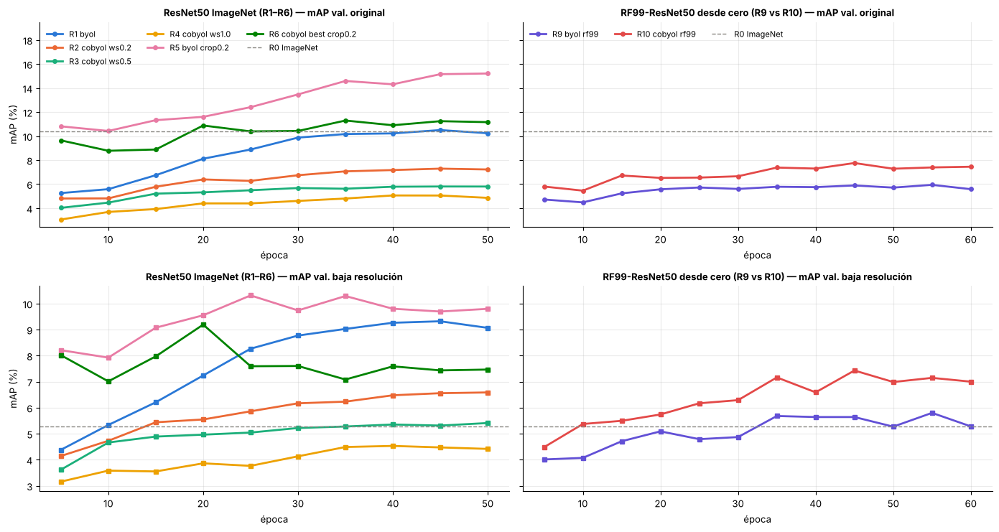

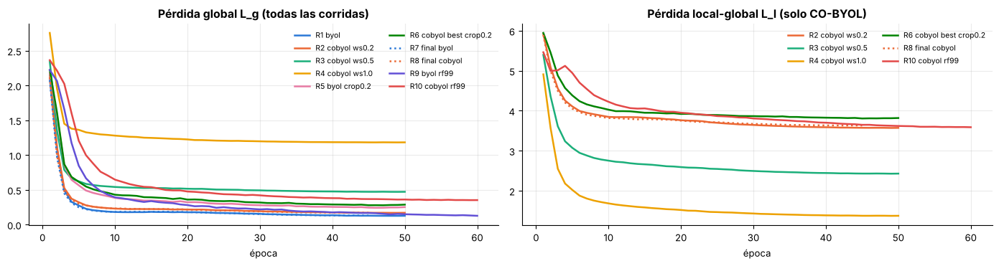

In [ ]:
groups = [('ResNet50 ImageNet (R1–R6)', [n for n in val_runs if ALL[n]['cfg']['arch'] == 'resnet50']),
          ('RF99-ResNet50 desde cero (R9 vs R10)', [n for n in val_runs if ALL[n]['cfg']['arch'] == 'rf99'])]
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharey='row')
for j, (gt, runs) in enumerate(groups):
    for n in runs:
        v = ALL[n]['hist']['val']
        e = [r['epoch'] for r in v]
        axes[0, j].plot(e, [r['mAP_orig'] for r in v], marker='o', ms=4, lw=2, color=COLOR[n], label=SHORT[n])
        axes[1, j].plot(e, [r['mAP_low'] for r in v], marker='s', ms=4, lw=2, color=COLOR[n], label=SHORT[n])
    for i, t in enumerate(['mAP val. original', 'mAP val. baja resolución']):
        axes[i, j].axhline(R0_VAL['mAP_orig' if i == 0 else 'mAP_low'], ls='--', lw=1, color=GRAY, label='R0 ImageNet')
        axes[i, j].set_title(f'{gt} — {t}', fontsize=9.5); axes[i, j].set_xlabel('época')
    axes[0, j].legend(fontsize=8, frameon=False, loc='upper left', ncol=3)
axes[0, 0].set_ylim(top=19.5)
axes[0, 0].set_ylabel('mAP (%)'); axes[1, 0].set_ylabel('mAP (%)')
plt.tight_layout(); save(fig, '11_curvas_mAP_todas')

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for n, s in ALL.items():
    ls = ':' if 'final' in n else '-'
    axes[0].plot(s['hist']['epoch'], s['hist']['L_g'], ls=ls, lw=1.8, color=COLOR[n], label=SHORT[n])
    if s['cfg']['w_s'] > 0:
        axes[1].plot(s['hist']['epoch'], s['hist']['L_l'], ls=ls, lw=1.8, color=COLOR[n], label=SHORT[n])
axes[0].set_title('Pérdida global L_g (todas las corridas)'); axes[1].set_title('Pérdida local-global L_l (solo CO-BYOL)')
for ax in axes: ax.set_xlabel('época'); ax.legend(fontsize=7.5, frameon=False, ncol=2)
plt.tight_layout(); save(fig, '11_curvas_perdidas_todas')

### 11.4 Sensibilidad al peso de la pérdida local `w_s` (contraste con la Tabla 7 del paper)

En el paper (ImageNet-100, RF99-ResNet50) el rendimiento sube de BYOL (w_s = 0) a un óptimo en w_s ∈ [0.2, 0.5]. En nuestro barrido (ResNet50 ImageNet, Re-ID) se mide mAP; las escalas no son comparables, por eso se grafican en paneles separados y se compara la **forma** de la curva.

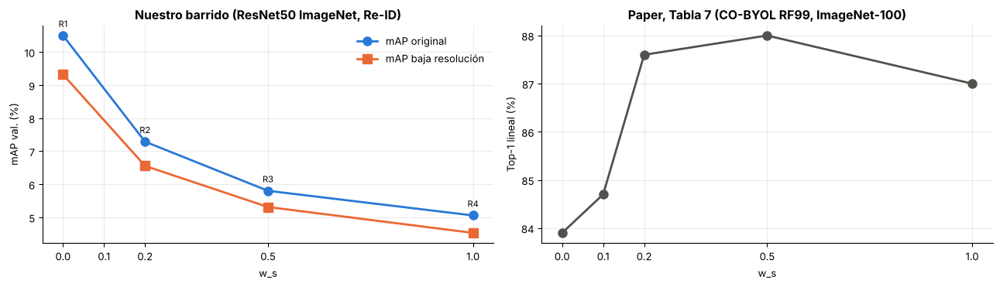

Tendencia observada: el mAP cae de forma monótona al subir w_s con ResNet50 ImageNet; en el paper la curva es creciente hasta w_s≈0.5.


In [ ]:
ws_runs = [n for n in val_runs if ALL[n]['cfg']['arch'] == 'resnet50' and ALL[n]['cfg']['crop_min_scale'] == 0.8]
ws_runs = sorted(ws_runs, key=lambda n: ALL[n]['cfg']['w_s'])
ws = [ALL[n]['cfg']['w_s'] for n in ws_runs]
m_o = [best_val(ALL[n])['mAP_orig'] for n in ws_runs]
m_l = [best_val(ALL[n])['mAP_low'] for n in ws_runs]
PAPER_T7 = {0: 83.9, 0.1: 84.7, 0.2: 87.6, 0.5: 88.0, 1.0: 87.0}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].plot(ws, m_o, marker='o', ms=8, lw=2, color='#2a78d6', label='mAP original')
axes[0].plot(ws, m_l, marker='s', ms=8, lw=2, color='#eb6834', label='mAP baja resolución')
for x, y, n in zip(ws, m_o, ws_runs):
    axes[0].annotate(n.split('_')[0], (x, y), textcoords='offset points', xytext=(0, 8), ha='center', fontsize=8)
axes[0].set_title('Nuestro barrido (ResNet50 ImageNet, Re-ID)'); axes[0].set_ylabel('mAP val. (%)')
axes[1].plot(list(PAPER_T7), list(PAPER_T7.values()), marker='o', ms=8, lw=2, color='#52514e')
axes[1].set_title('Paper, Tabla 7 (CO-BYOL RF99, ImageNet-100)'); axes[1].set_ylabel('Top-1 lineal (%)')
for ax in axes: ax.set_xlabel('w_s'); ax.set_xticks([0, 0.1, 0.2, 0.5, 1.0])
axes[0].legend(frameon=False)
plt.tight_layout(); save(fig, '11_sensibilidad_ws')
print('Tendencia observada: el mAP cae de forma monótona al subir w_s con ResNet50 ImageNet;',
      'en el paper la curva es creciente hasta w_s≈0.5.')

### 11.5 Ablación del recorte: ¿la pérdida local reemplaza al recorte agresivo?

Diseño 2×2 {BYOL, CO-BYOL} × {recorte suave 0.8, agresivo 0.2}. Según el paper (Fig. 4), la ventaja de CO-BYOL debería ser **mayor con recorte suave** (la pérdida local sustituye parcialmente a C/R).

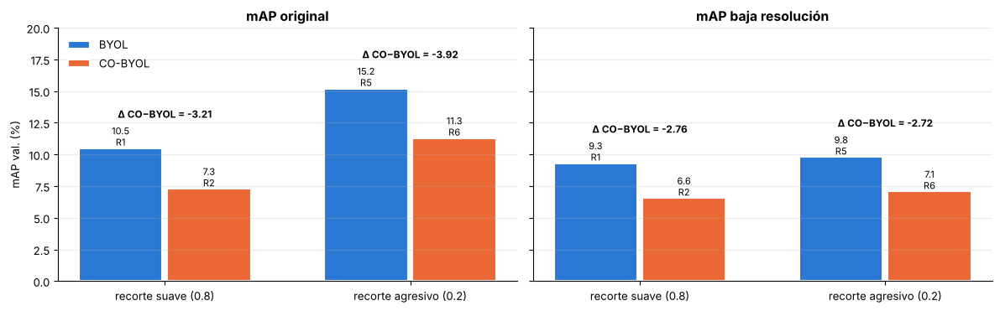

In [ ]:
best_co = max([n for n in ws_runs if ALL[n]['cfg']['w_s'] > 0], key=lambda n: ALL[n]['best_val_mAP'])
cells_2x2 = {('suave 0.8', 'BYOL'): 'R1_byol', ('suave 0.8', 'CO-BYOL'): best_co,
             ('agresivo 0.2', 'BYOL'): 'R5_byol_crop0.2', ('agresivo 0.2', 'CO-BYOL'): 'R6_cobyol_best_crop0.2'}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, k, t in [(axes[0], 'mAP_orig', 'mAP original'), (axes[1], 'mAP_low', 'mAP baja resolución')]:
    for i, crop in enumerate(['suave 0.8', 'agresivo 0.2']):
        for j, met in enumerate(['BYOL', 'CO-BYOL']):
            n = cells_2x2[(crop, met)]
            if n not in ALL: continue
            v = best_val(ALL[n])[k]
            ax.bar(i + (j - 0.5) * 0.36, v, width=0.34, color=['#2a78d6', '#eb6834'][j], edgecolor='white', lw=1.5,
                   label=met if i == 0 else None)
            ax.text(i + (j - 0.5) * 0.36, v + 0.2, f'{v:.1f}\n{n.split("_")[0]}', ha='center', fontsize=8)
        b, c = (best_val(ALL[cells_2x2[(crop, m)]])[k] for m in ['BYOL', 'CO-BYOL'])
        ax.text(i, max(b, c) + 2.4, f'Δ CO−BYOL = {c - b:+.2f}', ha='center', fontsize=8.5, fontweight='bold')
    ax.set_xticks([0, 1], ['recorte suave (0.8)', 'recorte agresivo (0.2)']); ax.set_title(t); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('mAP val. (%)'); axes[0].legend(frameon=False); axes[0].set_ylim(0, 20)
plt.tight_layout(); save(fig, '11_ablacion_recorte')

### 11.6 Arquitectura × pérdida: ResNet50 ImageNet vs RF99-ResNet50 (análogo a la Tabla 6 del paper)

Dentro de cada arquitectura, la diferencia CO-BYOL − BYOL aísla el aporte de la pérdida local-global. El paper reporta que la ganancia existe en ambas, pero **es mayor con RF99** (campo receptivo limitado, ~99 px). R9 vs R10 es la comparación más limpia: misma arquitectura, mismos datos y 60 épocas observadas en ambas. Diferencias restantes: R9 se configuró para 100 épocas y se detuvo en la 60 por el límite de 8 h, así que su LR (coseno) seguía alto al cortar, mientras R10 completó su schedule de 60 épocas; además el `done.json` de R9 registra batch 128 y el de R10 batch 64.

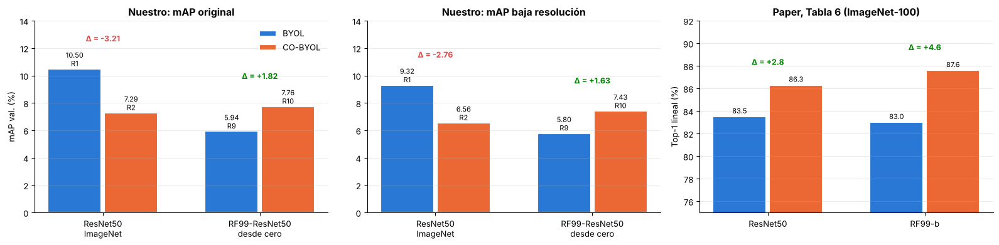

,arquitectura,BYOL,CO-BYOL,mAP BYOL,mAP CO-BYOL,ganancia,mAP baja BYOL,mAP baja CO-BYOL,ganancia baja
0,ResNet50 ImageNet,R1_byol,R2_cobyol_ws0.2,10.50,7.29,-3.21,9.32,6.56,-2.76
1,RF99-ResNet50 desde cero,R9_byol_rf99,R10_cobyol_rf99,5.94,7.76,1.82,5.80,7.43,1.63


In [ ]:
arch_pairs = [('ResNet50\nImageNet', 'R1_byol', best_co), ('RF99-ResNet50\ndesde cero', 'R9_byol_rf99', 'R10_cobyol_rf99')]
PAPER_T6 = {'ResNet50': (83.5, 86.3), 'RF99-b': (83.0, 87.6)}

fig, axes = plt.subplots(1, 3, figsize=(16, 4), gridspec_kw={'width_ratios': [1, 1, 1]})
tab = []
for ax, k, t in [(axes[0], 'mAP_orig', 'Nuestro: mAP original'), (axes[1], 'mAP_low', 'Nuestro: mAP baja resolución')]:
    for i, (lab, b, c) in enumerate(arch_pairs):
        vb, vc = best_val(ALL[b])[k], best_val(ALL[c])[k]
        for j, (n, v) in enumerate([(b, vb), (c, vc)]):
            ax.bar(i + (j - 0.5) * 0.36, v, width=0.34, color=['#2a78d6', '#eb6834'][j], edgecolor='white', lw=1.5,
                   label=['BYOL', 'CO-BYOL'][j] if i == 0 else None)
            ax.text(i + (j - 0.5) * 0.36, v + 0.2, f'{v:.2f}\n{n.split("_")[0]}', ha='center', fontsize=8)
        ax.text(i, max(vb, vc) + 2.0, f'Δ = {vc - vb:+.2f}', ha='center', fontsize=9, fontweight='bold',
                color='#008300' if vc > vb else '#e34948')
        if k == 'mAP_orig': tab.append({'arquitectura': lab.replace('\n', ' '), 'BYOL': b, 'CO-BYOL': c,
                                        'mAP BYOL': round(vb, 2), 'mAP CO-BYOL': round(vc, 2), 'ganancia': round(vc - vb, 2)})
        else: tab[i].update({'mAP baja BYOL': round(vb, 2), 'mAP baja CO-BYOL': round(vc, 2), 'ganancia baja': round(vc - vb, 2)})
    ax.set_xticks([0, 1], [p[0] for p in arch_pairs]); ax.set_title(t); ax.set_ylim(0, 14); ax.grid(axis='x', visible=False)
axes[0].set_ylabel('mAP val. (%)'); axes[0].legend(frameon=False, loc='upper right')
ax = axes[2]
for i, (lab, (b, c)) in enumerate(PAPER_T6.items()):
    for j, v in enumerate([b, c]):
        ax.bar(i + (j - 0.5) * 0.36, v, width=0.34, color=['#2a78d6', '#eb6834'][j], edgecolor='white', lw=1.5)
        ax.text(i + (j - 0.5) * 0.36, v + 0.3, f'{v}', ha='center', fontsize=8)
    ax.text(i, max(b, c) + 1.8, f'Δ = {c - b:+.1f}', ha='center', fontsize=9, fontweight='bold', color='#008300')
ax.set_xticks([0, 1], list(PAPER_T6)); ax.set_ylim(75, 92); ax.set_ylabel('Top-1 lineal (%)')
ax.set_title('Paper, Tabla 6 (ImageNet-100)'); ax.grid(axis='x', visible=False)
plt.tight_layout(); save(fig, '11_ablacion_arquitectura')
display(pd.DataFrame(tab))

original        : CO-BYOL supera a BYOL en 12/12 evaluaciones; ganancia media +1.36
baja resolución : CO-BYOL supera a BYOL en 12/12 evaluaciones; ganancia media +1.25


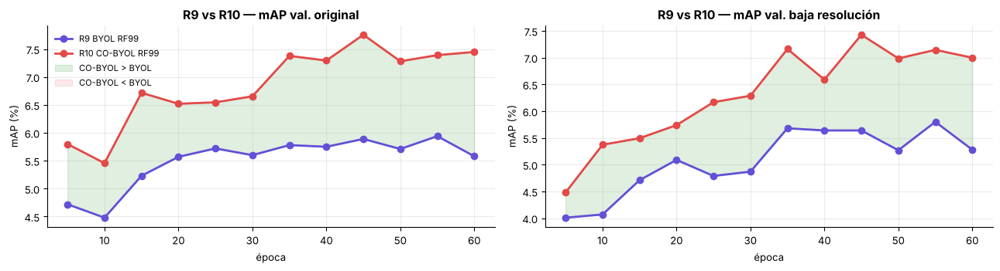

In [ ]:
# R9 vs R10 época a época (misma arquitectura y presupuesto): ¿CO-SSL aprende más rápido?
r9, r10 = ALL['R9_byol_rf99']['hist']['val'], ALL['R10_cobyol_rf99']['hist']['val']
common = sorted(set(r['epoch'] for r in r9) & set(r['epoch'] for r in r10))
g9 = {r['epoch']: r for r in r9}; g10 = {r['epoch']: r for r in r10}
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, k, t in [(axes[0], 'mAP_orig', 'original'), (axes[1], 'mAP_low', 'baja resolución')]:
    a = np.array([g9[e][k] for e in common]); b = np.array([g10[e][k] for e in common])
    ax.plot(common, a, marker='o', lw=2, color=COLOR['R9_byol_rf99'], label='R9 BYOL RF99')
    ax.plot(common, b, marker='o', lw=2, color=COLOR['R10_cobyol_rf99'], label='R10 CO-BYOL RF99')
    ax.fill_between(common, a, b, where=b >= a, color='#008300', alpha=0.12, interpolate=True, label='CO-BYOL > BYOL')
    ax.fill_between(common, a, b, where=b < a, color='#e34948', alpha=0.12, interpolate=True, label='CO-BYOL < BYOL')
    ax.set_title(f'R9 vs R10 — mAP val. {t}'); ax.set_xlabel('época'); ax.set_ylabel('mAP (%)')
    print(f'{t:16s}: CO-BYOL supera a BYOL en {int((b > a).sum())}/{len(common)} evaluaciones; ganancia media {np.mean(b - a):+.2f}')
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, '11_R9_vs_R10')

### 11.7 Robustez a baja resolución y curvas CMC

- **Izquierda:** mAP original vs mAP con query de baja resolución. Los puntos cercanos a la diagonal pierden poco al bajar la resolución (robustez), análogo a la robustez a corrupciones de las Tablas 4–5 del paper.
- **Derecha:** curvas CMC (Rank-1/5/10) del mejor checkpoint de cada corrida.

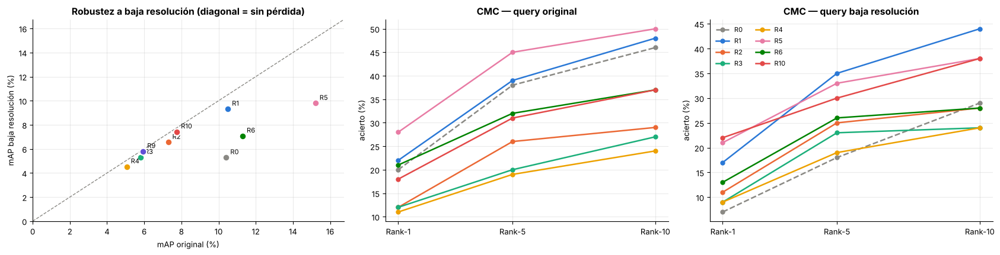

R9 no guarda Rank-5/10 en su done.json (reconstruido desde el log), por eso no aparece en las CMC.


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={'width_ratios': [1.1, 1, 1]})
ax = axes[0]
pts = [('R0_imagenet', R0_VAL)] + [(n, best_val(ALL[n])) for n in val_runs]
lim = max(p[1]['mAP_orig'] for p in pts) * 1.1
ax.plot([0, lim], [0, lim], ls='--', lw=1, color=GRAY)
for n, r in pts:
    ax.scatter(r['mAP_orig'], r['mAP_low'], s=70, color=COLOR[n], edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(n.split('_')[0], (r['mAP_orig'], r['mAP_low']), textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_xlabel('mAP original (%)'); ax.set_ylabel('mAP baja resolución (%)')
ax.set_title('Robustez a baja resolución (diagonal = sin pérdida)')
for ax, suf, t in [(axes[1], 'orig', 'CMC — query original'), (axes[2], 'low', 'CMC — query baja resolución')]:
    for n, r in pts:
        if f'R5_{suf}' not in r: continue
        ax.plot([1, 5, 10], [r[f'R1_{suf}'], r[f'R5_{suf}'], r[f'R10_{suf}']], marker='o', lw=1.8, ms=5,
                color=COLOR[n], ls='--' if n == 'R0_imagenet' else '-', label=n.split('_')[0])
    ax.set_xticks([1, 5, 10], ['Rank-1', 'Rank-5', 'Rank-10']); ax.set_ylabel('acierto (%)'); ax.set_title(t)
axes[2].legend(frameon=False, fontsize=8, ncol=2)
plt.tight_layout(); save(fig, '11_robustez_y_CMC')
print('R9 no guarda Rank-5/10 en su done.json (reconstruido desde el log), por eso no aparece en las CMC.')

### 11.8 Coste computacional

El paper (Tabla 2) reporta que CO-SSL añade un sobrecoste moderado con ResNet50 y casi duplica el tiempo con RF99 (mapas de características más grandes: 16×8 = 128 vectores locales frente a 8×4 = 32).

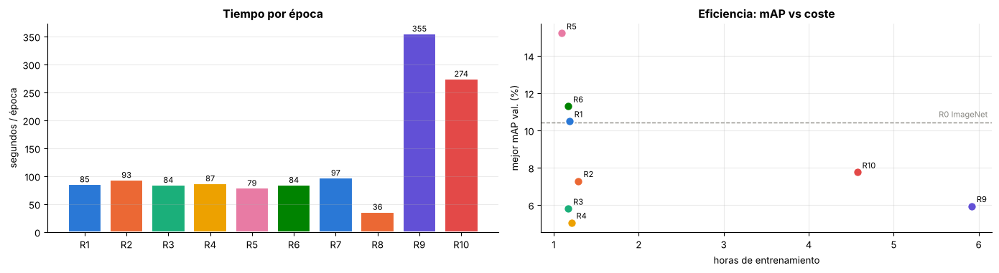

Nota: los s/época dependen del nodo y la carga del clúster del clúster; R7 y R8 compartieron job y nodo con distinta carga.


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 3.9))
runs_c = list(ALL)
x = np.arange(len(runs_c))
spe = [ALL[n]['sec_per_epoch'] for n in runs_c]
hrs = [ALL[n]['sec_per_epoch'] * len(ALL[n]['hist']['epoch']) / 3600 for n in runs_c]
axes[0].bar(x, spe, color=[COLOR[n] for n in runs_c], edgecolor='white', lw=1.5)
for xi, v in zip(x, spe): axes[0].text(xi, v + 4, f'{v:.0f}', ha='center', fontsize=8)
axes[0].set_xticks(x, [n.split('_')[0] for n in runs_c]); axes[0].set_ylabel('segundos / época')
axes[0].set_title('Tiempo por época'); axes[0].grid(axis='x', visible=False)
ax = axes[1]
for n in val_runs:
    h = ALL[n]['sec_per_epoch'] * len(ALL[n]['hist']['epoch']) / 3600
    ax.scatter(h, best_val(ALL[n])['mAP_orig'], s=80, color=COLOR[n], edgecolor='white', linewidth=1.5, zorder=3)
    ax.annotate(n.split('_')[0], (h, best_val(ALL[n])['mAP_orig']), textcoords='offset points', xytext=(5, 4), fontsize=8)
ax.axhline(R0_VAL['mAP_orig'], ls='--', lw=1, color=GRAY); ax.text(0.99, R0_VAL['mAP_orig'] + 0.3, 'R0 ImageNet', fontsize=8, color=GRAY, ha='right', transform=ax.get_yaxis_transform())
ax.set_xlabel('horas de entrenamiento'); ax.set_ylabel('mejor mAP val. (%)'); ax.set_title('Eficiencia: mAP vs coste')
plt.tight_layout(); save(fig, '11_coste_computacional')
print('Nota: los s/época dependen del nodo y la carga del clúster del clúster; R7 y R8 compartieron job y nodo con distinta carga.')

### 11.9 Resultados en test (evaluación única)

Test: 3 368 queries (750 identidades), 19 732 imágenes de galería; cada modelo se evaluó **una sola vez**, en ambas condiciones. R0, R7 (BYOL final) y R8 (CO-BYOL final) se evaluaron en la ejecución principal; **R9 y R10** (RF99-ResNet50, desde cero) se evaluaron después con su mejor checkpoint de validación (`best_encoder.pt`, entrenados solo con `training.h5`, sin reentrenamiento final) mediante `eval_test_local.py`, que reutiliza las funciones de la sección 7. Las filas correspondientes están en `runs/test_results.json`.


,mAP_orig,R1_orig,R5_orig,R10_orig,mAP_low,R1_low,R5_low,R10_low,delta_mAP
modelo,,,,,,,,,
R0_imagenet,3.13,9.89,20.37,26.37,1.54,3.24,8.43,12.56,1.59
R7_final_byol,2.85,8.64,18.02,24.08,2.64,7.51,17.43,23.28,0.21
R8_final_cobyol,2.12,6.18,13.03,16.83,2.00,5.55,11.79,16.48,0.12
R9_byol_rf99,1.29,3.27,9.41,13.57,1.10,2.02,7.10,10.45,0.19
R10_cobyol_rf99,2.34,7.33,16.51,22.15,2.18,5.64,14.79,20.58,0.16


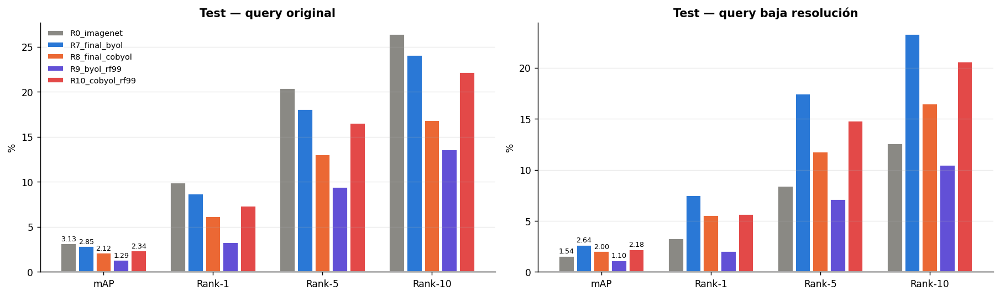

In [ ]:
TEST_DF = pd.DataFrame(json.loads((RUNS / 'test_results.json').read_text())).set_index('modelo')
display(TEST_DF)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
mods = list(TEST_DF.index)
cols = [COLOR.get(m, GRAY) for m in mods]
for ax, cond, t in [(axes[0], 'orig', 'Test — query original'), (axes[1], 'low', 'Test — query baja resolución')]:
    w = 0.26
    for i, m in enumerate(mods):
        vals = [TEST_DF.loc[m, f'{k}_{cond}'] for k in ['mAP', 'R1', 'R5', 'R10']]
        ax.bar(np.arange(4) + (i - 1) * w, vals, width=w - 0.02, color=cols[i], edgecolor='white', lw=1, label=m)
        ax.text(0 + (i - 1) * w, vals[0] + 0.4, f'{vals[0]:.2f}', ha='center', fontsize=7.5)
    ax.set_xticks(range(4), ['mAP', 'Rank-1', 'Rank-5', 'Rank-10']); ax.set_title(t); ax.set_ylabel('%')
    ax.grid(axis='x', visible=False)
axes[0].legend(frameon=False, fontsize=8)
plt.tight_layout(); save(fig, '11_test')

### 11.10 Conclusiones de la comparación (contraste con el paper)

1. **Mejor corrida en validación:** R5 (BYOL + recorte agresivo 0.2, ResNet50 ImageNet) con mAP ≈ 15.2 %, seguida de R6 (CO-BYOL + recorte 0.2, ≈ 11.3 %) y R1 (BYOL, ≈ 10.5 %). Con ResNet50 preentrenada, el recorte agresivo es la intervención que más aporta.
2. **`w_s` con ResNet50 (R1→R4):** el mAP baja de forma monótona al aumentar `w_s` (10.5 → 7.3 → 5.8 → 5.1). Esto **contradice** la Tabla 7 del paper (óptimo en 0.2–0.5). Una explicación coherente con el propio paper: con ResNet50 el campo receptivo de `layer4` (~425 px) es mayor que la imagen, así que los vectores "locales" no son partes; forzarlos a parecerse al global colapsa la información espacial que Re-ID necesita.
3. **Ablación de recorte:** CO-BYOL queda por debajo de BYOL con ambos recortes (−3.2 y −3.9). No se observa que la pérdida local sustituya al recorte agresivo con ResNet50.
4. **RF99-ResNet50 (R9 vs R10):** es la comparación fiel al paper y la única donde **CO-BYOL supera a BYOL**: 7.76 vs 5.94 de mAP (+1.8) y también en baja resolución (7.43 vs 5.80). Época a época, R10 supera a R9 en las 12 evaluaciones (+1.4 de media). Esto coincide cualitativamente con la Tabla 6: la pérdida local-global aporta más cuando el campo receptivo es limitado (~99 px), porque entonces los vectores locales sí representan partes del cuerpo.
5. **Desde cero vs preentrenado:** R9/R10 (desde cero, 11 043 imágenes, 60 épocas) quedan por debajo de R0 (ImageNet sin SSL). Con tan pocos datos, el preentrenamiento de ImageNet pesa más que el método SSL; el paper usa 100–1000 épocas sobre ImageNet completo.
6. **Baja resolución:** el SSL con augmentación de baja resolución reduce la brecha orig–baja (R0: Δ = 5.1; R1: Δ = 1.2; R9: Δ = 0.14; R10: Δ = 0.33), lo que es coherente con la robustez que el paper atribuye a CO-SSL (Tablas 4–5).
7. **Test (ResNet50):** R7 (BYOL) supera a R8 (CO-BYOL ResNet50) en ambas condiciones y mejora mucho a R0 en baja resolución (mAP 2.64 vs 1.54), aunque R0 sigue siendo mejor con la query original (3.13).
7b. **Test (RF99-ResNet50):** se repite el patrón de validación: **R10 (CO-BYOL) casi duplica a R9 (BYOL)**, mAP 2.34 vs 1.29 y Rank-1 7.33 vs 3.27 % (baja resolución: 2.18 vs 1.10). Es la única pareja donde la pérdida local-global ayuda también en test, coherente con la Tabla 6 del paper. R10 supera además a R8 (2.12) pese a entrenarse desde cero, solo con `training.h5` y sin reentrenamiento final, aunque queda por debajo de R7 y de R0 en query original. Los checkpoints `last` dan casi lo mismo (R9 1.31, R10 2.41), así que el resultado no depende de la selección de época. Todos los modelos SSL mantienen una caída orig→baja muy pequeña (Δ mAP 0.12–0.21) frente a R0 (1.59).
7c. **Validación vs test:** todas las cifras caen ~3–4× de validación (100 queries, 1 793 de galería) a test (3 368 queries, 19 732 de galería, 750 identidades): la galería es 11× mayor y hay muchos más distractores por identidad, de modo que el mAP de validación sirve para ordenar configuraciones pero no anticipa el nivel absoluto en test.
8. **Coste:** R10 tarda ~3× más por época que las corridas ResNet50 (mapa local de 128 vectores), en línea con el sobrecoste de RF99 reportado en la Tabla 2 del paper.

**Nota:** validación con 100 queries y una sola semilla; R9 fue interrumpida a las 60 de 100 épocas configuradas (su LR no llegó a decaer como en R10) y su `done.json` registra batch 128 frente a 64 en R10, así que la comparación R9 vs R10 es "mismo presupuesto de 60 épocas", no "mismos hiperparámetros". R9 y R10 se evaluaron en test con el mejor checkpoint de validación, sin reentrenamiento final con training + validación (a diferencia de R7/R8).